# SMS Spam Detection — Machine Learning Project

## Project Objective

The objective is to automatically classify an SMS text message as **spam** or **ham (legitimate)** using its text content and a few simple message-level characteristics (length, digits, capital letters, symbols, links, currency signs).

* **Problem type:** Supervised **Classification** (binary: ham = 0, spam = 1)
* **Dataset:** SMS Spam Collection (UCI ML Repository / Kaggle) — https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
* **Business problem:** Spam SMS annoys customers, carries fraud / phishing risk and damages trust in a mobile operator or messaging service. A good filter must **catch spam (high recall)** without **blocking genuine messages (high precision)**.

## Project Workflow

| Week | Activities |
|---|---|
| Week 1 | Problem understanding, EDA, preprocessing, feature encoding, 70:30 split, baseline classification (Logistic Regression, Decision Tree, KNN) |
| Week 2 | Random Forest, XGBoost, class-imbalance handling (class weights + SMOTE), GridSearchCV, cross-validation, ROC curve and AUC |
| Week 4 | Final model selection, feature importance, business insights, limitations, future improvements |

## Methodology

- Target variable: `label` → encoded as `label_num` (ham = 0, spam = 1)
- Train-test split: **70 : 30** (stratified, so the spam ratio is the same in both parts)
- Evaluation metrics: Accuracy, Precision, Recall, F1 Score, Confusion Matrix, ROC curve and AUC
- Validation: 5-fold **Stratified** cross-validation on the training data only
- Class imbalance: handled with **class weights** and **SMOTE**
- Text → numbers: TF-IDF (fitted **inside** a pipeline, so the test set never influences the vocabulary → no data leakage)

---

## 0. Setup — libraries and helper functions

In [1]:
!pip install -q xgboost imbalanced-learn kagglehub

In [2]:
# ---------------------------------------------------------------
# Imports, global settings and helper functions
# ---------------------------------------------------------------
import os, re, glob, zipfile, io, random, textwrap, warnings, time, urllib.request
warnings.filterwarnings("ignore")

# Data handling
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Machine learning
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV, cross_validate)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import MaxAbsScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_curve, precision_recall_curve, average_precision_score)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import joblib

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
sns.set_theme(style="whitegrid")

# Folder where every figure is stored
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    # Save the current matplotlib figure to figures/<name>.png and show it.
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=130, bbox_inches="tight")
    plt.show()

def say(text, width=110):
    # Print a wrapped paragraph (used for the auto-generated interpretations).
    print(textwrap.fill(text, width=width))

print("All libraries imported successfully!")

All libraries imported successfully!


---
# WEEK 1 — Problem Understanding & Data Exploration

## 1.1 Understanding the business problem

**Business / scientific problem.** Mobile users receive large volumes of unsolicited promotional and fraudulent SMS messages (prize draws, premium-rate numbers, "urgent" account alerts, phishing links). Operators, banks and messaging apps need an automatic filter that reads a message and decides whether it is **spam** or **ham**.

**Why machine learning?** Fixed keyword rules ("free", "win") are easy to bypass and also block genuine messages. A supervised model learns the *combination* of words and message patterns that separates spam from normal conversation.

**Two kinds of mistakes have different costs:**

| Error | Meaning | Impact |
|---|---|---|
| **False Negative** | Spam delivered as ham | Customer annoyance, fraud / phishing exposure |
| **False Positive** | Genuine message blocked as spam | Customer misses an important message (OTP, bank alert, friend) — usually the more harmful error |

Because the classes are **imbalanced** (far more ham than spam), plain *accuracy* is misleading; **Precision, Recall, F1 and AUC** are used together with accuracy.

## 1.2 Dataset — loading from the official source

The dataset is the **SMS Spam Collection** (5,574 English SMS messages, tagged ham / spam), published by the UCI Machine Learning Repository and mirrored on Kaggle. The cell below looks for the file in the Colab / local folders, then downloads it automatically from the official **Kaggle** source (`uciml/sms-spam-collection-dataset`), then from the official **UCI** source, and finally lets you **upload `spam.csv` manually** (Colab).

In [3]:
# ---------------------------------------------------------------
# Locate / download the dataset
#   Kaggle file : spam.csv            (columns v1 = label, v2 = text, + empty Unnamed columns, latin-1 encoding)
#   UCI file    : SMSSpamCollection   (tab separated: label <TAB> text)
# ---------------------------------------------------------------
CANDIDATE_FOLDERS = ["/content", "/content/data", "/data", "data", ".",
                     "/kaggle/input/sms-spam-collection-dataset"]

def read_kaggle_csv(path):
    return pd.read_csv(path, encoding="latin-1")

def read_uci_file(path):
    return pd.read_csv(path, sep="\t", header=None, names=["v1", "v2"], encoding="latin-1", quoting=3)

def find_local_file():
    for folder in CANDIDATE_FOLDERS:
        p = os.path.join(folder, "spam.csv")
        if os.path.isfile(p):
            return p, read_kaggle_csv
        p = os.path.join(folder, "SMSSpamCollection")
        if os.path.isfile(p):
            return p, read_uci_file
    return None, None

def load_sms_dataset():
    # 1) local / Colab folders
    path, reader = find_local_file()
    if path:
        return reader(path), f"local file: {path}"

    # 2) official Kaggle source (kagglehub)
    try:
        import kagglehub
        folder = kagglehub.dataset_download("uciml/sms-spam-collection-dataset")
        for root, _, files in os.walk(folder):
            if "spam.csv" in files:
                return read_kaggle_csv(os.path.join(root, "spam.csv")), "official Kaggle source (kagglehub)"
    except Exception as err:
        print("Kaggle download not possible:", str(err)[:120])

    # 3) official UCI source
    try:
        url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
        with urllib.request.urlopen(url, timeout=60) as r:
            z = zipfile.ZipFile(io.BytesIO(r.read()))
        with z.open("SMSSpamCollection") as f:
            df = pd.read_csv(f, sep="\t", header=None, names=["v1", "v2"], encoding="latin-1", quoting=3)
        return df, "official UCI repository"
    except Exception as err:
        print("UCI download not possible:", str(err)[:120])

    # 4) manual upload (Google Colab)
    try:
        from google.colab import files
        print("Please upload spam.csv (from https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset)")
        uploaded = files.upload()
        name = list(uploaded.keys())[0]
        return read_kaggle_csv(name), "manual upload"
    except Exception as err:
        raise FileNotFoundError(
            "Dataset not found. Download spam.csv from "
            "https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset and place it next to this notebook "
            "(Colab: left sidebar -> Files -> upload).") from err

raw, source_info = load_sms_dataset()
print("Dataset loaded from:", source_info)
print("Raw shape:", raw.shape)
display(raw.head())

Using Colab cache for faster access to the 'sms-spam-collection-dataset' dataset.
Dataset loaded from: official Kaggle source (kagglehub)
Raw shape: (5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


## 1.3 Dataset description — size, feature types and target variable

In [4]:
# ---------------------------------------------------------------
# Clean column names and describe the dataset
# ---------------------------------------------------------------
print("RAW DATASET INFORMATION")
raw.info()

# The Kaggle file has 3 extra almost-empty 'Unnamed' columns -> report them, then drop them
junk_cols = [c for c in raw.columns if str(c).startswith("Unnamed")]
if junk_cols:
    print("\nAlmost-empty extra columns found in the raw file:")
    print((raw[junk_cols].notnull().mean() * 100).round(2).astype(str) + " % filled")

df = raw[["v1", "v2"]].copy()
df.columns = ["label", "message"]
df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].astype(str)

print("\nDATASET SIZE (after keeping the two useful columns)")
print("Rows (messages) :", df.shape[0])
print("Columns         :", df.shape[1])

print("\nTARGET VARIABLE: label")
counts = df["label"].value_counts()
summary = pd.DataFrame({"Count": counts, "Percentage": (counts / len(df) * 100).round(2)})
display(summary)

print("\nFEATURE TYPES")
display(pd.DataFrame({
    "Column": ["label", "message"],
    "Data type": [str(df["label"].dtype), str(df["message"].dtype)],
    "Kind": ["Categorical (nominal, binary) — TARGET", "Unstructured text — main input feature"],
    "Unique values": [df["label"].nunique(), df["message"].nunique()],
}))
display(df.sample(8, random_state=SEED))

RAW DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB

Almost-empty extra columns found in the raw file:
Unnamed: 2     0.9 % filled
Unnamed: 3    0.22 % filled
Unnamed: 4    0.11 % filled
dtype: object

DATASET SIZE (after keeping the two useful columns)
Rows (messages) : 5572
Columns         : 2

TARGET VARIABLE: label


,Count,Percentage
label,,
ham,4825,86.59
spam,747,13.41



FEATURE TYPES


,Column,Data type,Kind,Unique values
0,label,object,"Categorical (nominal, binary) — TARGET",2
1,message,object,Unstructured text — main input feature,5169


,label,message
3245,ham,"Funny fact Nobody teaches volcanoes 2 erupt, t..."
944,ham,I sent my scores to sophas and i had to do sec...
1044,spam,We know someone who you know that fancies you....
2484,ham,Only if you promise your getting out as SOON a...
812,spam,Congratulations ur awarded either å£500 of CD ...
2973,ham,"I'll text carlos and let you know, hang on"
2991,ham,K.i did't see you.:)k:)where are you now?
2942,ham,No message..no responce..what happend?


**Feature-type explanation**

* **`label` (target, categorical / nominal, binary):** `ham` = legitimate message, `spam` = unwanted message. It must be encoded as 0 / 1 for the models (section 1.9).
* **`message` (text):** the raw SMS. A model cannot read raw text, so it is converted to numbers with **TF-IDF** (section 1.9). This is the main input feature.
* **Engineered numerical features:** the dataset has no numeric columns of its own, so message-level numeric features are created in the next section (length, word count, digit count, capital letters, special characters, link flag, currency flag). They are used for distribution, outlier and correlation analysis and also as extra model inputs.
* **Extra `Unnamed` columns (Kaggle file only):** almost entirely empty (comment fragments) → dropped.

## 1.4 Missing value analysis and duplicates

In [5]:
# ---------------------------------------------------------------
# Missing value analysis
# ---------------------------------------------------------------
print("MISSING VALUE ANALYSIS")
missing = pd.DataFrame({
    "Missing values": df.isnull().sum(),
    "Missing %": (df.isnull().mean() * 100).round(3),
})
display(missing)
print("Total missing values:", int(df.isnull().sum().sum()))

# Empty / blank messages are also a kind of missing information
blank = (df["message"].str.strip() == "").sum()
print("Blank messages      :", int(blank))
print("Labels other than ham/spam:", int((~df["label"].isin(["ham", "spam"])).sum()))

MISSING VALUE ANALYSIS


,Missing values,Missing %
label,0,0.0
message,0,0.0


Total missing values: 0
Blank messages      : 0
Labels other than ham/spam: 0


In [6]:
# ---------------------------------------------------------------
# Duplicate messages
# The SMS collection contains the same text several times (typically repeated spam campaigns).
# If identical messages were in BOTH the train and the test set, the model would be "tested" on texts it has
# already seen (data leakage), so exact duplicates are removed BEFORE the split.
# ---------------------------------------------------------------
n_before = len(df)
dup_rows = df.duplicated(subset=["label", "message"]).sum()
print("Duplicate (label, message) rows:", dup_rows)
print("Spam share among the duplicates:",
      round(100 * df[df.duplicated(subset=['label', 'message'], keep='first')]['label'].eq('spam').mean(), 1), "%")

# Same text with conflicting labels would be ambiguous -> check
conflict = df.groupby("message")["label"].nunique()
print("Messages that appear with both labels:", int((conflict > 1).sum()))

df = df.drop_duplicates(subset=["label", "message"]).reset_index(drop=True)
print(f"\nShape before: {n_before} rows  ->  after removing duplicates: {len(df)} rows")
print(df["label"].value_counts(normalize=True).mul(100).round(2).rename("Percentage").to_string())

Duplicate (label, message) rows: 403
Spam share among the duplicates: 23.3 %
Messages that appear with both labels: 0

Shape before: 5572 rows  ->  after removing duplicates: 5169 rows
label
ham     87.37
spam    12.63


**Missing-value interpretation.** The table above shows that the two useful columns contain **no missing values**, so no imputation is required (the only almost-empty columns were the extra `Unnamed` columns of the Kaggle file, which were dropped). Exact **duplicate messages were removed** (mostly repeated spam texts) so that identical texts cannot appear in both the training and the test set.

## 1.5 Feature engineering for exploration (numerical message characteristics)

Spam messages tend to be longer, contain more digits (phone numbers, prices, short codes), more capital letters ("FREE", "WIN"), links and currency symbols. These simple numeric descriptors let us run distribution, outlier and correlation analysis on a text problem.

In [7]:
# ---------------------------------------------------------------
# Numeric descriptors of every message (they are also reused later as model inputs)
# ---------------------------------------------------------------
NUM_COLS = ["msg_length", "word_count", "avg_word_length", "digit_count",
            "upper_count", "special_char_count", "has_url", "has_currency"]

def add_features(frame):
    frame = frame.copy()
    m = frame["message"].astype(str)
    frame["msg_length"] = m.str.len()
    frame["word_count"] = m.str.split().str.len()
    frame["avg_word_length"] = frame["msg_length"] / frame["word_count"].clip(lower=1)
    frame["digit_count"] = m.str.count(r"\d")
    frame["upper_count"] = m.str.count(r"[A-Z]")
    frame["special_char_count"] = m.str.count(r"[^A-Za-z0-9\s]")
    frame["has_url"] = m.str.contains(r"http|www\.|\.com|\.co\.uk", case=False, regex=True).astype(int)
    frame["has_currency"] = m.str.contains(r"[£$€]", regex=True).astype(int)
    return frame

df = add_features(df)
df["label_num"] = df["label"].map({"ham": 0, "spam": 1})   # target encoding (explained in 1.8)

print("STATISTICAL DESCRIPTION OF THE NUMERIC FEATURES")
display(df[NUM_COLS].describe().round(2))

print("\nAVERAGE VALUE PER CLASS")
display(df.groupby("label")[NUM_COLS].mean().round(2))

STATISTICAL DESCRIPTION OF THE NUMERIC FEATURES


,msg_length,word_count,avg_word_length,digit_count,upper_count,special_char_count,has_url,has_currency
count,5169.00,5169.00,5169.00,5169.00,5169.00,5169.00,5169.00,5169.00
mean,78.98,15.34,5.17,2.21,5.27,4.30,0.02,0.05
std,58.24,11.07,1.13,6.03,11.15,4.57,0.16,0.21
min,2.00,1.00,2.00,0.00,0.00,0.00,0.00,0.00
25%,36.00,7.00,4.57,0.00,1.00,2.00,0.00,0.00
50%,60.00,12.00,5.00,0.00,2.00,3.00,0.00,0.00
75%,117.00,22.00,5.57,1.00,4.00,6.00,0.00,0.00
max,910.00,171.00,49.00,47.00,128.00,133.00,1.00,1.00



AVERAGE VALUE PER CLASS


,msg_length,word_count,avg_word_length,digit_count,upper_count,special_char_count,has_url,has_currency
label,,,,,,,,
ham,70.46,14.13,5.05,0.29,3.83,3.98,0.00,0.00
spam,137.89,23.68,5.95,15.45,15.23,6.50,0.18,0.33


## 1.6 Distribution analysis

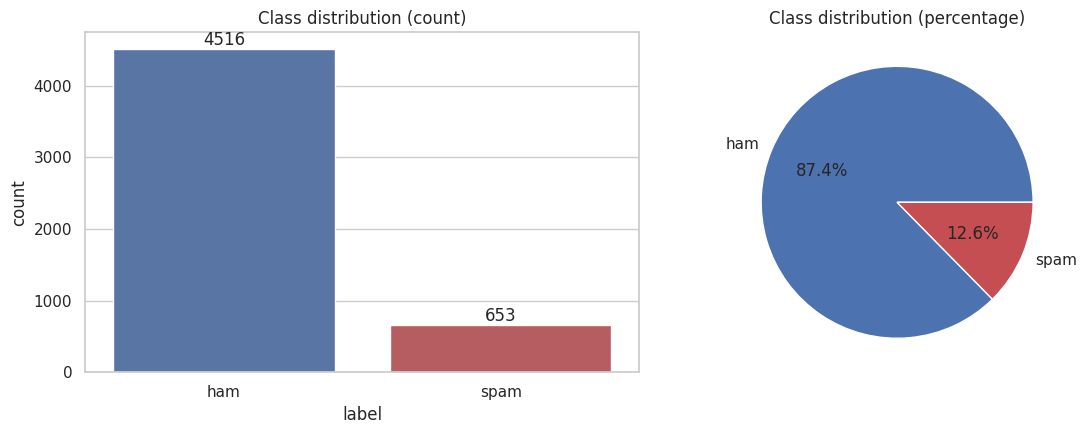

Interpretation (class balance): the dataset is clearly IMBALANCED - 87.4% ham versus 12.6% spam (about 6.9 ham
messages per spam message). A model that always answers 'ham' would already be 87.4% accurate while catching
no spam at all, so accuracy alone is not a reliable metric. Precision, Recall, F1, ROC-AUC and imbalance
handling (class weights / SMOTE) are therefore required.


In [8]:
# ---------------------------------------------------------------
# Target (class) distribution
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
order = ["ham", "spam"]
sns.countplot(data=df, x="label", order=order, palette=["#4C72B0", "#C44E52"], ax=axes[0])
axes[0].set_title("Class distribution (count)")
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
df["label"].value_counts().reindex(order).plot.pie(autopct="%1.1f%%", colors=["#4C72B0", "#C44E52"], ax=axes[1], ylabel="")
axes[1].set_title("Class distribution (percentage)")
save_fig("01_class_distribution")

ratio_ham_spam = (df["label_num"] == 0).sum() / (df["label_num"] == 1).sum()
say(f"Interpretation (class balance): the dataset is clearly IMBALANCED - {df['label'].eq('ham').mean()*100:.1f}% ham versus "
    f"{df['label'].eq('spam').mean()*100:.1f}% spam (about {ratio_ham_spam:.1f} ham messages per spam message). A model that always "
    f"answers 'ham' would already be {df['label'].eq('ham').mean()*100:.1f}% accurate while catching no spam at all, so accuracy alone "
    f"is not a reliable metric. Precision, Recall, F1, ROC-AUC and imbalance handling (class weights / SMOTE) are therefore required.")

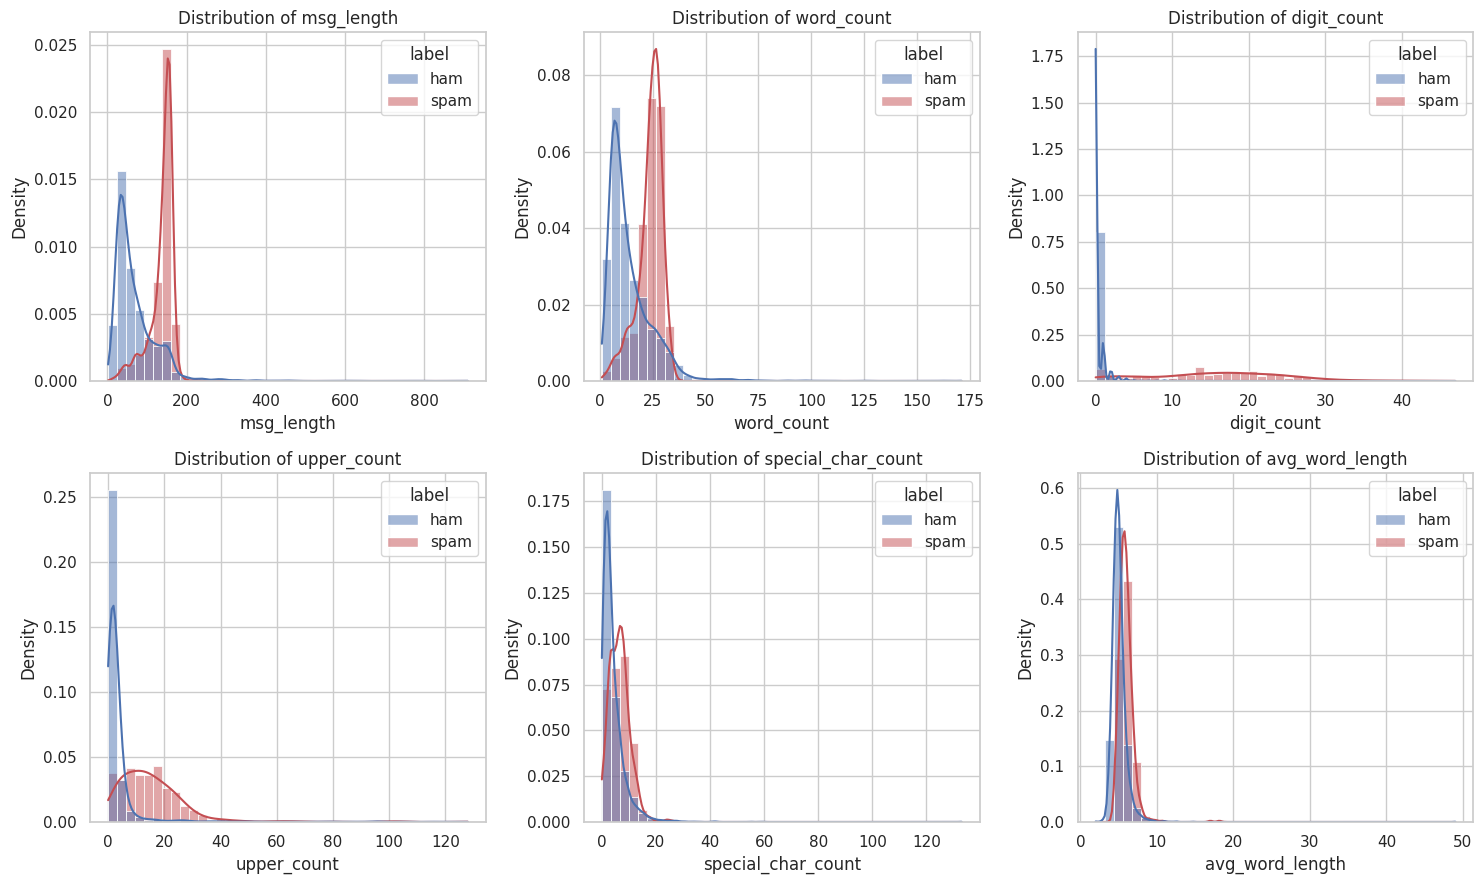

Skewness of each variable:
msg_length             2.61
word_count             2.74
digit_count            3.18
upper_count            5.90
special_char_count     6.60
avg_word_length       12.71


In [9]:
# ---------------------------------------------------------------
# Distribution of the numeric message features, split by class
# ---------------------------------------------------------------
dist_cols = ["msg_length", "word_count", "digit_count", "upper_count", "special_char_count", "avg_word_length"]
plt.figure(figsize=(15, 9))
for i, col in enumerate(dist_cols):
    plt.subplot(2, 3, i + 1)
    sns.histplot(data=df, x=col, hue="label", bins=40, kde=True, stat="density", common_norm=False,
                 palette={"ham": "#4C72B0", "spam": "#C44E52"})
    plt.title(f"Distribution of {col}")
save_fig("02_feature_distributions")

skew = df[dist_cols].skew().round(2)
print("Skewness of each variable:")
print(skew.to_string())

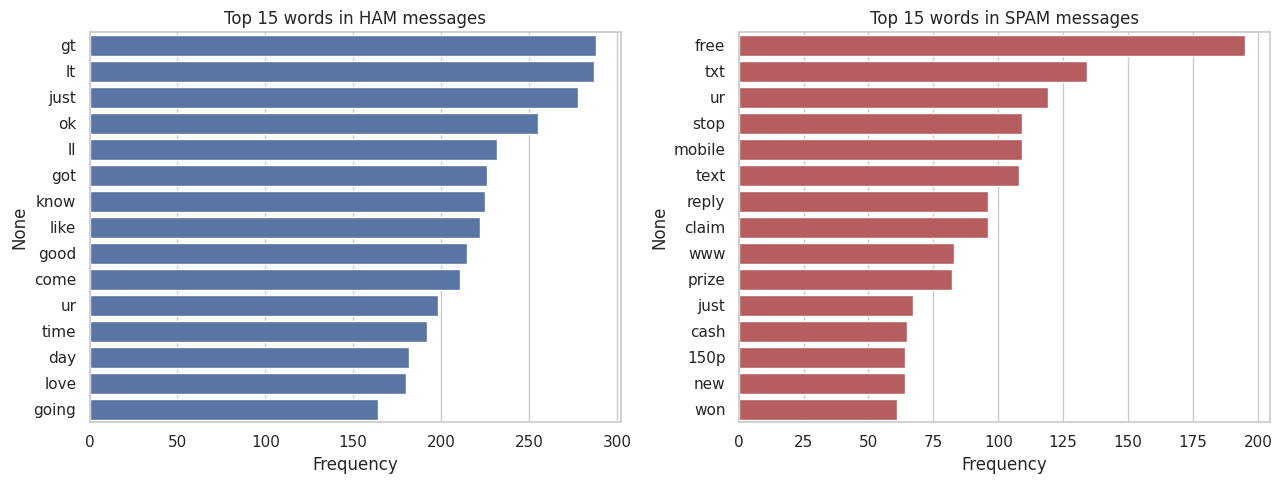

In [10]:
# ---------------------------------------------------------------
# Most frequent words per class (stop-words removed) - what do spam and ham talk about?
# ---------------------------------------------------------------
def top_words(texts, n=15):
    cv = CountVectorizer(stop_words="english", min_df=2)
    mat = cv.fit_transform(texts)
    freq = np.asarray(mat.sum(axis=0)).ravel()
    return pd.Series(freq, index=cv.get_feature_names_out()).sort_values(ascending=False).head(n)

TOPW = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (lab, colr) in zip(axes, [("ham", "#4C72B0"), ("spam", "#C44E52")]):
    tw = top_words(df.loc[df["label"] == lab, "message"])
    TOPW[lab] = tw
    sns.barplot(x=tw.values, y=tw.index, color=colr, ax=ax)
    ax.set_title(f"Top 15 words in {lab.upper()} messages")
    ax.set_xlabel("Frequency")
save_fig("03_top_words")

In [11]:
mean_len = df.groupby("label")["msg_length"].mean()
say(f"Interpretation (distributions): message length and word count are right-skewed (skewness {skew['msg_length']} and "
    f"{skew['word_count']}): most SMS are short, a few are very long. Spam messages are clearly longer on average "
    f"({mean_len['spam']:.0f} characters versus {mean_len['ham']:.0f} for ham) and contain more digits and capital letters "
    f"(phone numbers, prices, short codes, words like FREE / WIN). The most frequent spam words are "
    f"{', '.join(TOPW['spam'].index[:8])}, i.e. the vocabulary of calls to action and offers, whereas the most frequent ham words are "
    f"{', '.join(TOPW['ham'].index[:8])}, i.e. everyday conversation. "
    f"Because the numeric features are skewed and differ so much between classes, they are useful predictors, and models that do "
    f"not assume normality (tree-based models) are expected to work well.")

Interpretation (distributions): message length and word count are right-skewed (skewness 2.61 and 2.74): most
SMS are short, a few are very long. Spam messages are clearly longer on average (138 characters versus 70 for
ham) and contain more digits and capital letters (phone numbers, prices, short codes, words like FREE / WIN).
The most frequent spam words are free, txt, ur, stop, mobile, text, reply, claim, i.e. the vocabulary of calls
to action and offers, whereas the most frequent ham words are gt, lt, just, ok, ll, got, know, like, i.e.
everyday conversation. Because the numeric features are skewed and differ so much between classes, they are
useful predictors, and models that do not assume normality (tree-based models) are expected to work well.


## 1.7 Outlier detection

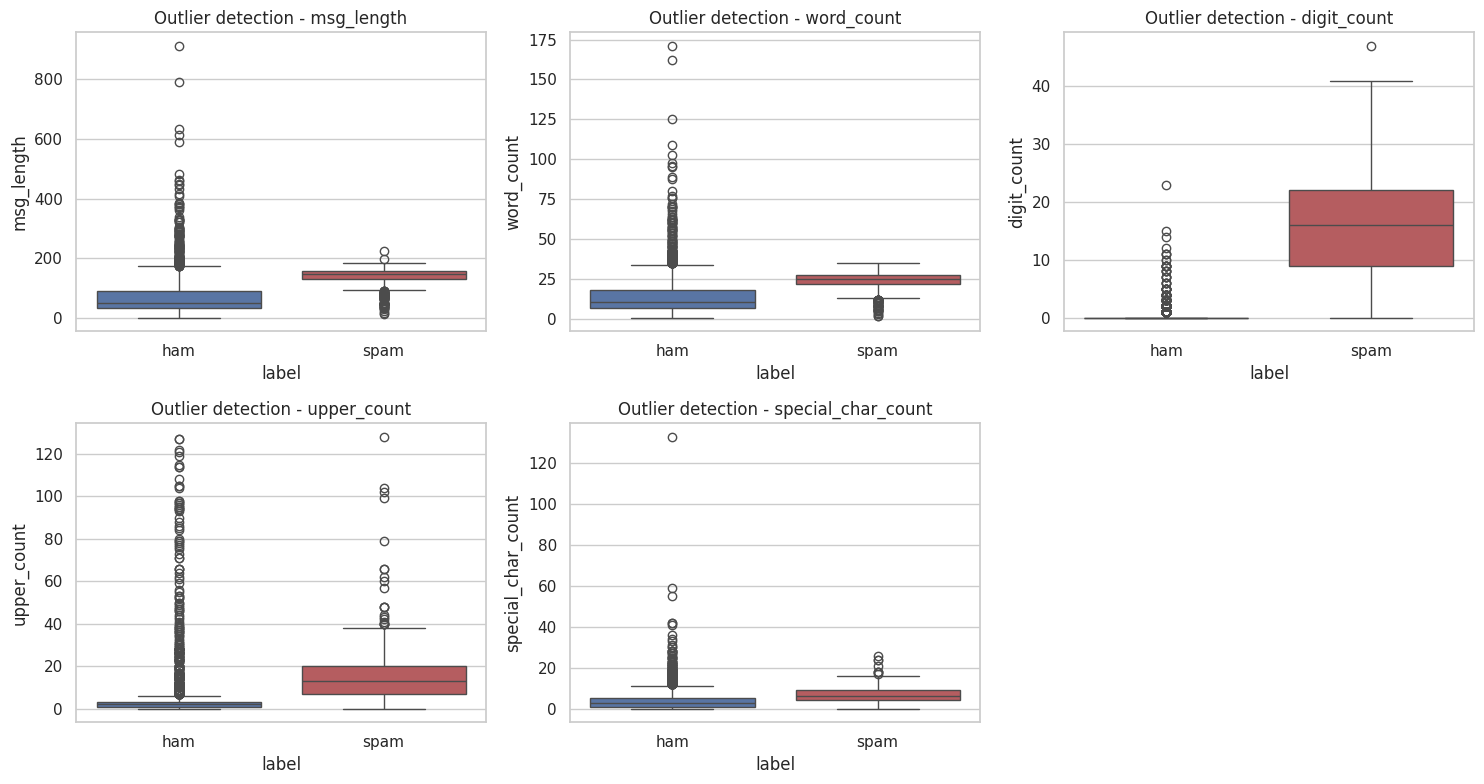

,Variable,Q1,Q3,Lower fence,Upper fence,Outliers,Outlier %,Spam share among outliers %
0,msg_length,36.0,117.0,-85.5,238.5,66,1.28,0.0
1,word_count,7.0,22.0,-15.5,44.5,68,1.32,0.0
2,digit_count,0.0,1.0,-1.5,2.5,705,13.64,82.6
3,upper_count,1.0,4.0,-3.5,8.5,704,13.62,64.2
4,special_char_count,2.0,6.0,-4.0,12.0,225,4.35,17.8


Messages with |z-score| > 3 for msg_length: 56
Longest message: 910 characters (SMS standard is 160 per segment; longer texts are concatenated messages)


In [12]:
# ---------------------------------------------------------------
# Outlier detection with box plots and the IQR rule (1.5 x IQR)
# ---------------------------------------------------------------
out_cols = ["msg_length", "word_count", "digit_count", "upper_count", "special_char_count"]
plt.figure(figsize=(15, 8))
for i, col in enumerate(out_cols):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(data=df, x="label", y=col, order=["ham", "spam"], palette=["#4C72B0", "#C44E52"])
    plt.title(f"Outlier detection - {col}")
save_fig("04_boxplots")

rows = []
for col in out_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[col] < low) | (df[col] > high)
    rows.append({"Variable": col, "Q1": q1, "Q3": q3, "Lower fence": round(low, 1), "Upper fence": round(high, 1),
                 "Outliers": int(mask.sum()), "Outlier %": round(100 * mask.mean(), 2),
                 "Spam share among outliers %": round(100 * df.loc[mask, "label_num"].mean(), 1) if mask.any() else 0})
outlier_table = pd.DataFrame(rows)
display(outlier_table)

z = np.abs(stats.zscore(df["msg_length"]))
print("Messages with |z-score| > 3 for msg_length:", int((z > 3).sum()))
print("Longest message:", df["msg_length"].max(), "characters (SMS standard is 160 per segment; longer texts are concatenated messages)")

In [13]:
ot = outlier_table.set_index("Variable")
say(f"Interpretation (outliers) and decision: the IQR rule flags {ot.loc['msg_length','Outliers']} unusually long messages "
    f"({ot.loc['msg_length','Outlier %']}%) - their spam share is {ot.loc['msg_length','Spam share among outliers %']}%, i.e. they are long, chatty "
    f"genuine texts (usually several SMS joined together). Digit count and capital-letter count have many more 'outliers' "
    f"({ot.loc['digit_count','Outliers']} and {ot.loc['upper_count','Outliers']}), and {ot.loc['digit_count','Spam share among outliers %']}% / "
    f"{ot.loc['upper_count','Spam share among outliers %']}% of them are spam (phone numbers, prices, SHOUTING words). All of these are GENUINE observations, "
    f"not sensor or entry errors, and many carry exactly the class information the model must learn, so removing or clipping them would "
    f"hurt. Decision: the outliers are KEPT. Tree-based models are insensitive to extreme values, and the numeric features are scaled "
    f"with MaxAbsScaler inside the pipeline for the linear / distance-based models.")

Interpretation (outliers) and decision: the IQR rule flags 66 unusually long messages (1.28%) - their spam
share is 0.0%, i.e. they are long, chatty genuine texts (usually several SMS joined together). Digit count and
capital-letter count have many more 'outliers' (705 and 704), and 82.6% / 64.2% of them are spam (phone
numbers, prices, SHOUTING words). All of these are GENUINE observations, not sensor or entry errors, and many
carry exactly the class information the model must learn, so removing or clipping them would hurt. Decision:
the outliers are KEPT. Tree-based models are insensitive to extreme values, and the numeric features are
scaled with MaxAbsScaler inside the pipeline for the linear / distance-based models.


## 1.8 Correlation analysis

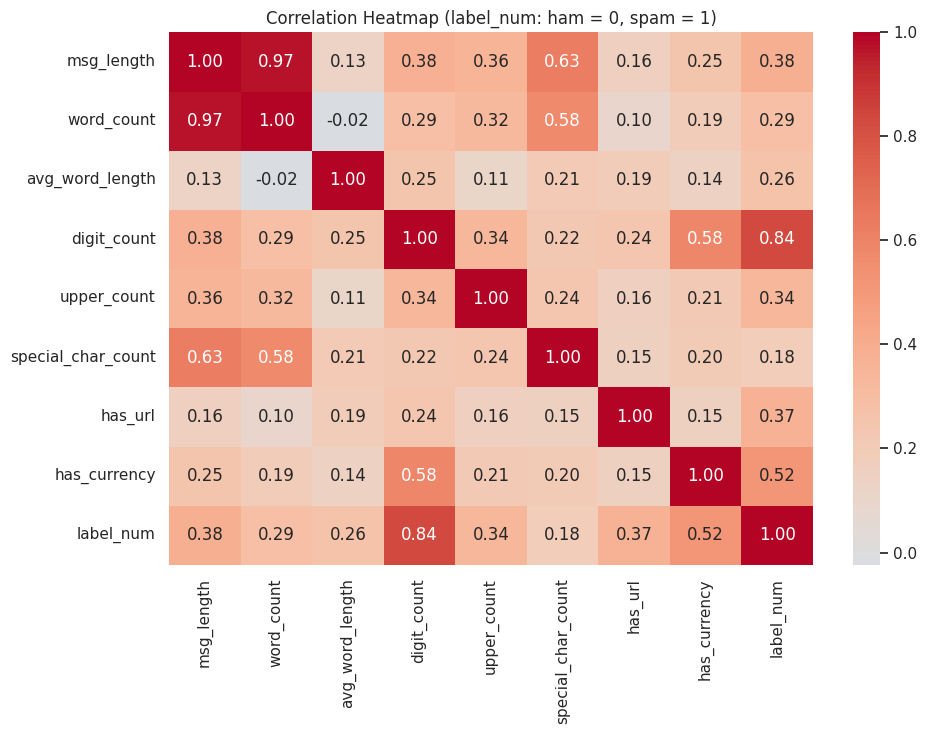

Correlation of every numerical feature with the target (point-biserial correlation):
digit_count           0.836
has_currency          0.524
msg_length            0.385
has_url               0.374
upper_count           0.340
word_count            0.287
avg_word_length       0.264
special_char_count    0.183

Feature pairs with |correlation| > 0.8:


,Feature 1,Feature 2,Correlation
0,msg_length,word_count,0.974


In [14]:
# ---------------------------------------------------------------
# Correlation analysis of the numeric features and the (encoded) target
# ---------------------------------------------------------------
numeric_data = df[NUM_COLS + ["label_num"]]
correlation = numeric_data.corr()

plt.figure(figsize=(10, 7.5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Heatmap (label_num: ham = 0, spam = 1)")
save_fig("05_correlation_heatmap")

corr_target = correlation["label_num"].drop("label_num").sort_values(key=np.abs, ascending=False)
print("Correlation of every numerical feature with the target (point-biserial correlation):")
print(corr_target.round(3).to_string())

# Highly inter-correlated feature pairs (multicollinearity check)
pairs = (correlation.loc[NUM_COLS, NUM_COLS].where(np.triu(np.ones((len(NUM_COLS),) * 2), 1).astype(bool))
         .stack().rename("corr").reset_index())
pairs.columns = ["Feature 1", "Feature 2", "Correlation"]
print("\nFeature pairs with |correlation| > 0.8:")
display(pairs[pairs["Correlation"].abs() > 0.8].sort_values("Correlation", ascending=False).round(3))

In [15]:
top3 = corr_target.head(3)
weakest = corr_target.index[-1]
high_pairs = pairs[pairs["Correlation"].abs() > 0.8]
pair_txt = "; ".join(f"{r['Feature 1']} & {r['Feature 2']} (r = {r['Correlation']:.2f})" for _, r in high_pairs.iterrows()) or "none"
say(f"Interpretation (correlation): the three numeric features most related to the spam label are "
    f"{', '.join(f'{k} (r = {v:.2f})' for k, v in top3.items())}. '{top3.index[0]}' is a very strong signal: spam messages are full of phone "
    f"numbers, prices and short codes. The weakest numeric feature is {weakest} (r = {corr_target.iloc[-1]:.2f}). Highly inter-correlated "
    f"pairs (|r| > 0.8): {pair_txt}; these carry overlapping information, which is harmless for tree models and handled by "
    f"regularisation in Logistic Regression. All correlations are linear and the numeric descriptors ignore WHAT the message says, so the "
    f"actual words (TF-IDF) are still needed to separate the harder cases.")

Interpretation (correlation): the three numeric features most related to the spam label are digit_count (r =
0.84), has_currency (r = 0.52), msg_length (r = 0.38). 'digit_count' is a very strong signal: spam messages
are full of phone numbers, prices and short codes. The weakest numeric feature is special_char_count (r =
0.18). Highly inter-correlated pairs (|r| > 0.8): msg_length & word_count (r = 0.97); these carry overlapping
information, which is harmless for tree models and handled by regularisation in Logistic Regression. All
correlations are linear and the numeric descriptors ignore WHAT the message says, so the actual words (TF-IDF)
are still needed to separate the harder cases.


## 1.9 Feature encoding

Models cannot use raw text or the words `ham` / `spam` directly, so the following encodings are applied:

| Original | Encoding | Reason |
|---|---|---|
| `label` (target, nominal, 2 classes) | `ham → 0`, `spam → 1` (label encoding) | binary target; **spam is the positive class**, so Precision / Recall / F1 describe how well spam is detected |
| `message` (text) | **TF-IDF** vectors (unigrams + bigrams, vocabulary limited to the 3,000 most informative terms, `min_df = 2`, sub-linear term frequency) | turns each message into numbers; words frequent in a message but rare overall (e.g. *claim*, *prize*) get high weights |
| numeric descriptors (length, digits, …) | `MaxAbsScaler` | brings all numeric inputs to a comparable scale without destroying sparsity |

Stop-words are **kept** on purpose: words such as *your*, *you*, *now* are strong spam signals in this data.

**No leakage:** the TF-IDF vocabulary and the scaler are learned **only on the training data**, because they are placed *inside* a scikit-learn `Pipeline` (fitted on the train part only, and re-fitted inside every cross-validation fold).

In [16]:
# ---------------------------------------------------------------
# Target encoding + the feature-transformation block used by every model
# ---------------------------------------------------------------
print("Target encoding check:")
print(df.groupby("label")["label_num"].first().to_string())

def make_preprocessor():
    return ColumnTransformer([
        ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2,
                                  max_features=3000, sublinear_tf=True), "message"),
        ("num", MaxAbsScaler(), NUM_COLS),
    ])

# Independent variables (input) and dependent variable (target)
INPUT_COLS = ["message"] + NUM_COLS
X = df[INPUT_COLS].copy()
y = df["label_num"].copy()

print("\nINPUT COLUMNS:", INPUT_COLS)
print("Input shape  :", X.shape)
print("Target shape :", y.shape)
print("Missing values in inputs:", int(X.isnull().sum().sum()))

Target encoding check:
label
ham     0
spam    1

INPUT COLUMNS: ['message', 'msg_length', 'word_count', 'avg_word_length', 'digit_count', 'upper_count', 'special_char_count', 'has_url', 'has_currency']
Input shape  : (5169, 9)
Target shape : (5169,)
Missing values in inputs: 0


## 1.10 Train-test split (70 : 30)

The messages are **independent texts** (there is no time order in this dataset), so a **random but stratified** split is used: 70 % of the messages for training and 30 % for testing, with the spam / ham proportion kept identical in both parts. The test set is used **only for the final evaluation**; all tuning and model comparison inside the training data is done with cross-validation.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)

print("TRAIN-TEST SPLIT (70 : 30)")
print("Train size:", X_train.shape[0], f"({len(X_train)/len(X)*100:.1f}%)")
print("Test size :", X_test.shape[0],  f"({len(X_test)/len(X)*100:.1f}%)")
print("\nSpam share in the full data :", round(y.mean() * 100, 2), "%")
print("Spam share in train         :", round(y_train.mean() * 100, 2), "%")
print("Spam share in test          :", round(y_test.mean() * 100, 2), "%")

# Prepared once only to report the size of the feature space (models use their own pipeline copy)
_tmp = make_preprocessor().fit(X_train)
print("\nFeature space after encoding:", _tmp.transform(X_train).shape[1], "columns",
      "(TF-IDF terms + numeric descriptors)")

TRAIN-TEST SPLIT (70 : 30)
Train size: 3618 (70.0%)
Test size : 1551 (30.0%)

Spam share in the full data : 12.63 %
Spam share in train         : 12.63 %
Spam share in test          : 12.64 %

Feature space after encoding: 3008 columns (TF-IDF terms + numeric descriptors)


## 1.11 Week 1 — EDA summary (2–3 page report content)

In [18]:
n_spam, n_ham = int((y == 1).sum()), int((y == 0).sum())
print("EDA SUMMARY")
print("=" * 70)
say(f"Problem: classify an SMS as spam or ham (binary supervised classification). Data: the SMS Spam Collection with {raw.shape[0]} raw "
    f"messages; after dropping empty helper columns and {n_before - len(df)} exact duplicates, {len(df)} unique messages remain "
    f"({n_ham} ham, {n_spam} spam = {n_spam/len(df)*100:.1f}% spam). There are no missing values. The only original features are the text "
    f"and the label, so 8 numeric descriptors were engineered. Spam messages are longer ({mean_len['spam']:.0f} vs {mean_len['ham']:.0f} "
    f"characters on average) and contain more digits and capital letters. Length-type variables are right-skewed and contain outliers, "
    f"which are genuine and therefore kept. The target is imbalanced, so Precision / Recall / F1 / AUC and imbalance handling are "
    f"used. Text is encoded with TF-IDF inside a pipeline and the data is split 70:30 (stratified): {len(X_train)} training and "
    f"{len(X_test)} test messages.")

EDA SUMMARY
Problem: classify an SMS as spam or ham (binary supervised classification). Data: the SMS Spam Collection with
5572 raw messages; after dropping empty helper columns and 403 exact duplicates, 5169 unique messages remain
(4516 ham, 653 spam = 12.6% spam). There are no missing values. The only original features are the text and
the label, so 8 numeric descriptors were engineered. Spam messages are longer (138 vs 70 characters on
average) and contain more digits and capital letters. Length-type variables are right-skewed and contain
outliers, which are genuine and therefore kept. The target is imbalanced, so Precision / Recall / F1 / AUC and
imbalance handling are used. Text is encoded with TF-IDF inside a pipeline and the data is split 70:30
(stratified): 3618 training and 1551 test messages.


---
# WEEK 1 (Part B) — Baseline Modeling (Classification)

Required classification baselines: **Logistic Regression, Decision Tree, KNN**.
Metrics: **Accuracy, Precision, Recall, F1 Score and Confusion Matrix** (plus ROC-AUC, which is also needed in Week 2).
*All baselines use default settings, **no** imbalance handling and are evaluated on exactly the same test set. Spam is the positive class.*

> Regression models (Linear Regression, MAE, RMSE, R²) are **not applicable** because the target is categorical.

## 1B.1 Training and evaluating the baselines

In [19]:
# Containers that store the results of every model
results = {}       # model name -> metrics
predictions = {}   # model name -> test-set class predictions
probabilities = {} # model name -> test-set spam probabilities
models = {}        # model name -> fitted model

def evaluate_model(name, model, X_eval, y_eval, verbose=True):
    pred = model.predict(X_eval)
    proba = model.predict_proba(X_eval)[:, 1]
    res = {
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred, zero_division=0),
        "F1 Score": f1_score(y_eval, pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_eval, proba),
    }
    results[name], predictions[name], probabilities[name], models[name] = res, pred, proba, model
    if verbose:
        print(f"{name:34s} Acc={res['Accuracy']:.4f}  Prec={res['Precision']:.4f}  "
              f"Rec={res['Recall']:.4f}  F1={res['F1 Score']:.4f}  AUC={res['ROC AUC']:.4f}")

def results_table(names=None):
    names = names or list(results.keys())
    t = pd.DataFrame({n: results[n] for n in names}).T.reset_index().rename(columns={"index": "Model"})
    return t.sort_values(["F1 Score", "ROC AUC"], ascending=False).reset_index(drop=True)

def plot_confusion_matrices(names, ncols=3, title_suffix=""):
    nrows = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.3 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, n in zip(axes, names):
        ConfusionMatrixDisplay.from_predictions(y_test, predictions[n], display_labels=["Ham", "Spam"],
                                                cmap="Blues", ax=ax, colorbar=False)
        ax.set_title(n + title_suffix, fontsize=10)
        ax.grid(False)
    for ax in axes[len(names):]:
        ax.axis("off")
    plt.tight_layout()

def make_pipeline(estimator):
    return Pipeline([("prep", make_preprocessor()), ("model", estimator)])

BASELINE_MODELS = ["Logistic Regression", "Decision Tree", "KNN Classifier"]
print("BASELINE MODEL RESULTS (test set)")
print("-" * 100)

# 1) Logistic Regression
lr_base = make_pipeline(LogisticRegression(max_iter=1000, random_state=SEED)).fit(X_train, y_train)
evaluate_model("Logistic Regression", lr_base, X_test, y_test)

# 2) Decision Tree
dt_base = make_pipeline(DecisionTreeClassifier(random_state=SEED)).fit(X_train, y_train)
evaluate_model("Decision Tree", dt_base, X_test, y_test)

# 3) KNN (cosine distance is the natural metric for TF-IDF vectors)
knn_base = make_pipeline(KNeighborsClassifier(n_neighbors=5, metric="cosine", algorithm="brute")).fit(X_train, y_train)
evaluate_model("KNN Classifier", knn_base, X_test, y_test)

BASELINE MODEL RESULTS (test set)
----------------------------------------------------------------------------------------------------
Logistic Regression                Acc=0.9755  Prec=0.9702  Rec=0.8316  F1=0.8956  AUC=0.9954
Decision Tree                      Acc=0.9800  Prec=0.9459  Rec=0.8929  F1=0.9186  AUC=0.9427
KNN Classifier                     Acc=0.9813  Prec=0.9563  Rec=0.8929  F1=0.9235  AUC=0.9746


Logistic Regression
              precision    recall  f1-score   support

         Ham     0.9761    0.9963    0.9861      1355
        Spam     0.9702    0.8316    0.8956       196

    accuracy                         0.9755      1551
   macro avg     0.9732    0.9140    0.9409      1551
weighted avg     0.9754    0.9755    0.9747      1551

Decision Tree
              precision    recall  f1-score   support

         Ham     0.9846    0.9926    0.9886      1355
        Spam     0.9459    0.8929    0.9186       196

    accuracy                         0.9800      1551
   macro avg     0.9653    0.9427    0.9536      1551
weighted avg     0.9797    0.9800    0.9798      1551

KNN Classifier
              precision    recall  f1-score   support

         Ham     0.9846    0.9941    0.9893      1355
        Spam     0.9563    0.8929    0.9235       196

    accuracy                         0.9813      1551
   macro avg     0.9705    0.9435    0.9564      1551
weighted avg     0.9811  

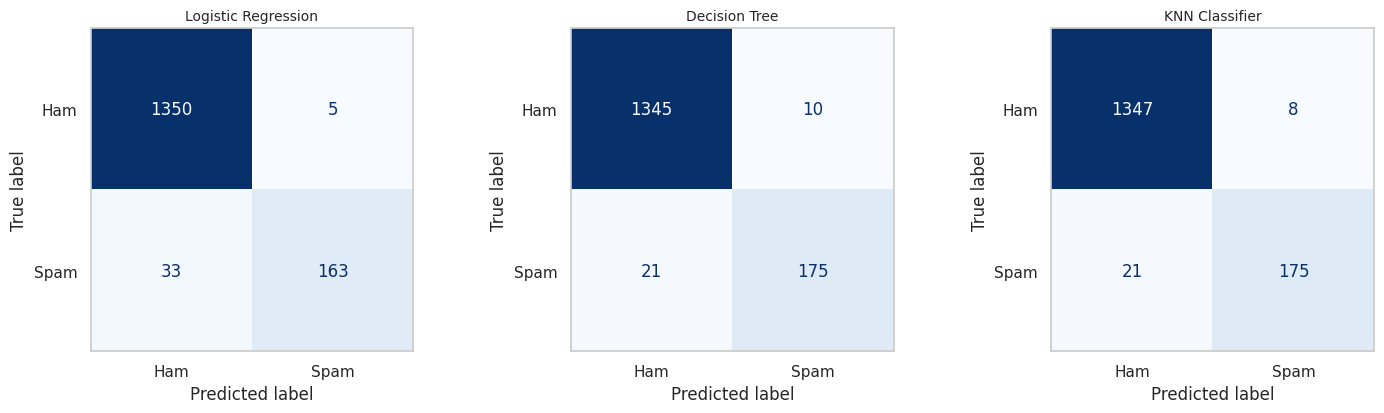

Reading a confusion matrix (rows = actual, columns = predicted):
  top-left = ham correctly kept | top-right = ham wrongly blocked (False Positive)
  bottom-left = spam missed (False Negative) | bottom-right = spam correctly caught


In [20]:
# Detailed per-class report and confusion matrices of the three baselines
for n in BASELINE_MODELS:
    print("=" * 60); print(n); print("=" * 60)
    print(classification_report(y_test, predictions[n], target_names=["Ham", "Spam"], digits=4))

plot_confusion_matrices(BASELINE_MODELS)
save_fig("06_baseline_confusion_matrices")

print("Reading a confusion matrix (rows = actual, columns = predicted):")
print("  top-left = ham correctly kept | top-right = ham wrongly blocked (False Positive)")
print("  bottom-left = spam missed (False Negative) | bottom-right = spam correctly caught")

## 1B.2 Baseline model comparison table

BASELINE MODEL COMPARISON TABLE (sorted by F1 score)


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,KNN Classifier,0.9813,0.9563,0.8929,0.9235,0.9746
1,Decision Tree,0.9800,0.9459,0.8929,0.9186,0.9427
2,Logistic Regression,0.9755,0.9702,0.8316,0.8956,0.9954


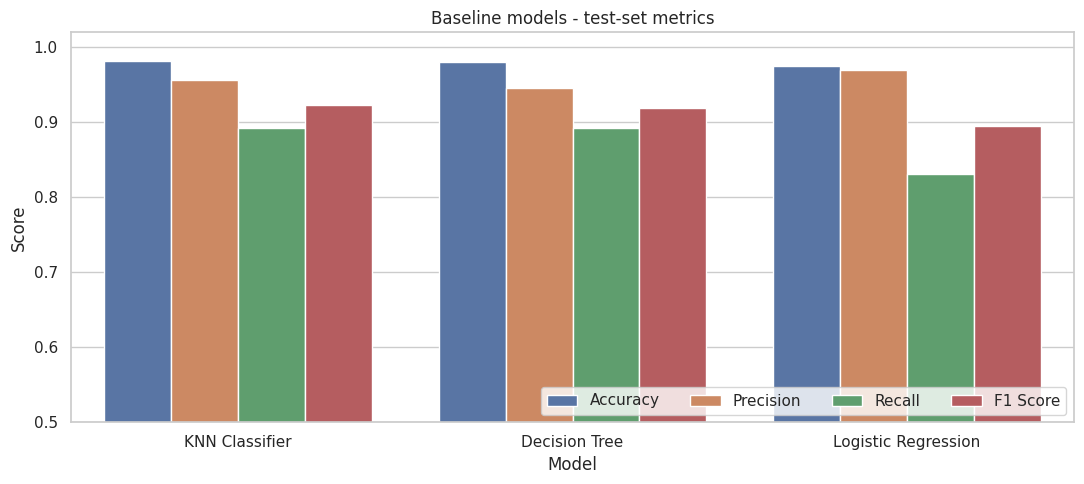

Reference: always predicting 'ham' gives accuracy = 0.8736, precision = recall = F1 = 0 for spam.


In [21]:
baseline_results = results_table(BASELINE_MODELS)
print("BASELINE MODEL COMPARISON TABLE (sorted by F1 score)")
display(baseline_results.round(4))

# Bar chart of the metrics
plot_df = baseline_results.melt(id_vars="Model", value_vars=["Accuracy", "Precision", "Recall", "F1 Score"],
                                var_name="Metric", value_name="Score")
plt.figure(figsize=(11, 5))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric")
plt.ylim(0.5, 1.02)
plt.title("Baseline models - test-set metrics")
plt.legend(loc="lower right", ncol=4)
save_fig("07_baseline_comparison")

# "Dumb" reference: always predict ham
majority_acc = 1 - y_test.mean()
print(f"Reference: always predicting 'ham' gives accuracy = {majority_acc:.4f}, precision = recall = F1 = 0 for spam.")

## 1B.3 Interpretation of the baseline results

In [22]:
best_b = baseline_results.iloc[0]
worst_b = baseline_results.iloc[-1]
cm_best = confusion_matrix(y_test, predictions[best_b["Model"]])
tn, fp, fn, tp = cm_best.ravel()
say(f"Interpretation (baselines): all three baselines are far above the 'always ham' accuracy of {majority_acc:.3f}, which shows that the "
    f"message text contains a strong spam signal. The best baseline is {best_b['Model']} (F1 = {best_b['F1 Score']:.3f}, precision = "
    f"{best_b['Precision']:.3f}, recall = {best_b['Recall']:.3f}); the weakest is {worst_b['Model']} (F1 = {worst_b['F1 Score']:.3f}). "
    f"For {best_b['Model']} the confusion matrix shows {tp} spam messages caught, {fn} spam messages missed (false negatives) and {fp} "
    f"genuine messages wrongly blocked (false positives). Accuracy is high for every model because ham dominates the data, so the "
    f"differences between the models are visible mainly in Recall and F1, i.e. in how many spam messages each model finds. "
    f"Linear / margin-based models work well on high-dimensional TF-IDF text, a single deep Decision Tree tends to over-fit rare "
    f"words, and KNN depends on the neighbourhood of similar messages. These results are the benchmark that the advanced models in "
    f"Week 2 must beat.")

Interpretation (baselines): all three baselines are far above the 'always ham' accuracy of 0.874, which shows
that the message text contains a strong spam signal. The best baseline is KNN Classifier (F1 = 0.923,
precision = 0.956, recall = 0.893); the weakest is Logistic Regression (F1 = 0.896). For KNN Classifier the
confusion matrix shows 175 spam messages caught, 21 spam messages missed (false negatives) and 8 genuine
messages wrongly blocked (false positives). Accuracy is high for every model because ham dominates the data,
so the differences between the models are visible mainly in Recall and F1, i.e. in how many spam messages each
model finds. Linear / margin-based models work well on high-dimensional TF-IDF text, a single deep Decision
Tree tends to over-fit rare words, and KNN depends on the neighbourhood of similar messages. These results are
the benchmark that the advanced models in Week 2 must beat.


---
# WEEK 2 — Advanced Modeling & Optimization

* **Class-imbalance handling:** class weights **and** SMOTE (compared with cross-validation)
* **Models:** Random Forest and **XGBoost** (gradient boosting)
* **Hyper-parameter tuning:** `GridSearchCV` (exhaustive grid, 5-fold stratified CV, scoring = F1 of the spam class)
* **Cross-validation:** 5-fold `StratifiedKFold` on the training data
* **Classification-specific analysis:** ROC curve, AUC score, precision-recall curve

(Residual analysis is a regression-only technique and is therefore not applicable here; feature importance is done in section 4.2.)

## 2.1 Handling class imbalance — class weights vs SMOTE

Only about 1 message in 8 is spam. Two standard remedies are compared:

* **Class weights:** the model is told that an error on a spam message costs more (`class_weight="balanced"`, or `scale_pos_weight` for XGBoost).
* **SMOTE:** creates *synthetic* spam examples in feature space so that both classes are equally frequent **in the training folds only** (never in validation / test data).

The comparison uses 5-fold stratified cross-validation on the **training set** (the test set stays untouched).

done: Logistic Regression | no handling      (5s)
done: Logistic Regression | class weights    (3s)
done: Logistic Regression | SMOTE            (2s)
done: Random Forest | no handling            (5s)
done: Random Forest | class weights          (7s)
done: Random Forest | SMOTE                  (7s)

CROSS-VALIDATED COMPARISON OF IMBALANCE STRATEGIES (training data, 5 folds)


,Model | strategy,Precision,Recall,F1,ROC AUC
0,Logistic Regression | no handling,0.9753,0.8402,0.9011,0.9945
1,Logistic Regression | class weights,0.9474,0.9256,0.9359,0.9944
2,Logistic Regression | SMOTE,0.9730,0.9322,0.9519,0.9924
3,Random Forest | no handling,0.9856,0.8949,0.9378,0.9939
4,Random Forest | class weights,0.9950,0.8818,0.9348,0.9951
5,Random Forest | SMOTE,0.9885,0.9365,0.9616,0.9950


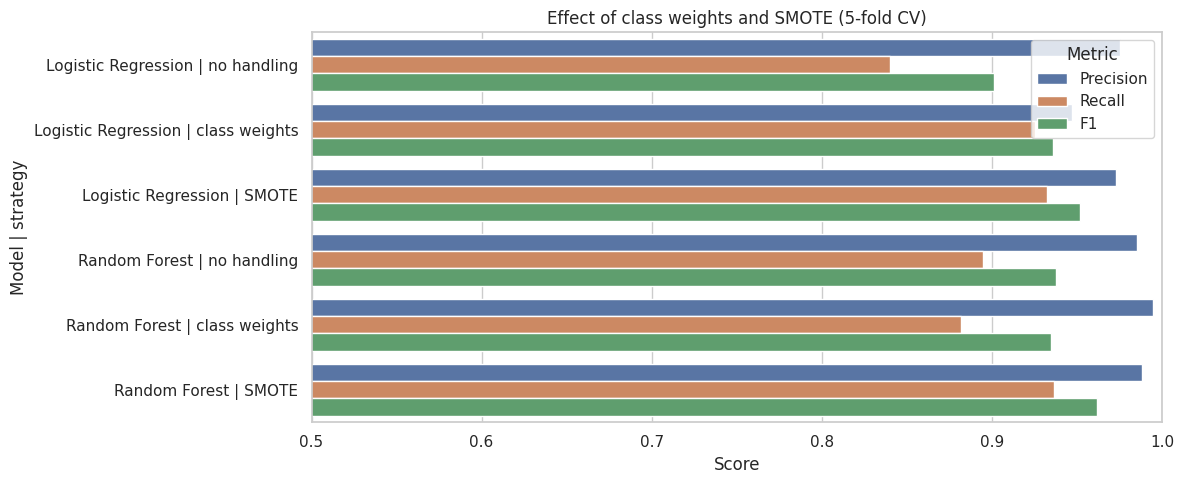

In [23]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

variants = {
    "Logistic Regression | no handling":    make_pipeline(LogisticRegression(max_iter=1000, random_state=SEED)),
    "Logistic Regression | class weights":  make_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
    "Logistic Regression | SMOTE":          ImbPipeline([("prep", make_preprocessor()), ("smote", SMOTE(random_state=SEED)),
                                                         ("model", LogisticRegression(max_iter=1000, random_state=SEED))]),
    "Random Forest | no handling":          make_pipeline(RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)),
    "Random Forest | class weights":        make_pipeline(RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1)),
    "Random Forest | SMOTE":                ImbPipeline([("prep", make_preprocessor()), ("smote", SMOTE(random_state=SEED)),
                                                         ("model", RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1))]),
}

rows = []
for name, pipe in variants.items():
    t0 = time.time()
    cvr = cross_validate(pipe, X_train, y_train, cv=cv5, scoring=scoring, n_jobs=1)
    rows.append({"Model | strategy": name,
                 "Precision": cvr["test_precision"].mean(), "Recall": cvr["test_recall"].mean(),
                 "F1": cvr["test_f1"].mean(), "ROC AUC": cvr["test_roc_auc"].mean()})
    print(f"done: {name:38s} ({time.time()-t0:.0f}s)")

imbalance_table = pd.DataFrame(rows)
print("\nCROSS-VALIDATED COMPARISON OF IMBALANCE STRATEGIES (training data, 5 folds)")
display(imbalance_table.round(4))

imb_plot = imbalance_table.melt(id_vars="Model | strategy", value_vars=["Precision", "Recall", "F1"], var_name="Metric", value_name="Score")
plt.figure(figsize=(12, 5))
sns.barplot(data=imb_plot, y="Model | strategy", x="Score", hue="Metric")
plt.xlim(0.5, 1.0)
plt.title("Effect of class weights and SMOTE (5-fold CV)")
save_fig("08_imbalance_handling")

In [24]:
by_f1 = imbalance_table.sort_values("F1", ascending=False).iloc[0]
lr_rows = imbalance_table[imbalance_table["Model | strategy"].str.startswith("Logistic")].set_index("Model | strategy")
say(f"Interpretation (imbalance): the best strategy in this comparison is '{by_f1['Model | strategy']}' (CV F1 = {by_f1['F1']:.3f}). "
    f"For Logistic Regression, class weights change recall from {lr_rows.loc['Logistic Regression | no handling','Recall']:.3f} to "
    f"{lr_rows.loc['Logistic Regression | class weights','Recall']:.3f}, and SMOTE gives {lr_rows.loc['Logistic Regression | SMOTE','Recall']:.3f}: "
    f"giving spam more importance mainly moves the Precision / Recall balance towards catching more spam (higher recall, slightly lower precision) "
    f"instead of adding new information. SMOTE builds synthetic points in a very high-dimensional TF-IDF space, whereas class weights are "
    f"free and simple. To let the data decide, the class-weight options are part of every GridSearchCV grid in section 2.3, and a "
    f"SMOTE-based Random Forest is tuned and cross-validated as a separate candidate.")

Interpretation (imbalance): the best strategy in this comparison is 'Random Forest | SMOTE' (CV F1 = 0.962).
For Logistic Regression, class weights change recall from 0.840 to 0.926, and SMOTE gives 0.932: giving spam
more importance mainly moves the Precision / Recall balance towards catching more spam (higher recall,
slightly lower precision) instead of adding new information. SMOTE builds synthetic points in a very high-
dimensional TF-IDF space, whereas class weights are free and simple. To let the data decide, the class-weight
options are part of every GridSearchCV grid in section 2.3, and a SMOTE-based Random Forest is tuned and
cross-validated as a separate candidate.


## 2.2 Random Forest and XGBoost (default settings)

Random Forest (bagging of many decision trees) and XGBoost (gradient-boosted trees) are the two required advanced models. First they are trained with default settings, then tuned in section 2.3.

In [25]:
neg, pos = int((y_train == 0).sum()), int((y_train == 1).sum())
imbalance_ratio = neg / pos
print(f"Training data: {neg} ham / {pos} spam  ->  imbalance ratio = {imbalance_ratio:.2f}")

rf_default = make_pipeline(RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)).fit(X_train, y_train)
evaluate_model("Random Forest (Default)", rf_default, X_test, y_test)

xgb_default = make_pipeline(XGBClassifier(objective="binary:logistic", eval_metric="logloss", tree_method="hist",
                                          random_state=SEED, n_jobs=-1)).fit(X_train, y_train)
evaluate_model("XGBoost (Default)", xgb_default, X_test, y_test)

Training data: 3161 ham / 457 spam  ->  imbalance ratio = 6.92
Random Forest (Default)            Acc=0.9839  Prec=0.9942  Rec=0.8776  F1=0.9322  AUC=0.9956
XGBoost (Default)                  Acc=0.9832  Prec=0.9474  Rec=0.9184  F1=0.9326  AUC=0.9893


## 2.3 Hyper-parameter tuning with GridSearchCV

Every model gets an **exhaustive grid** (all combinations are tried) evaluated with **5-fold stratified cross-validation** on the training data; the scoring metric is **F1 of the spam class** (the right choice for an imbalanced problem). The grids also contain the class-imbalance options (`class_weight` / `scale_pos_weight`), so the search decides whether weighting is useful. Because the vectoriser is inside the pipeline, it is re-fitted in every fold (no leakage).



In [26]:
grid_specs = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=SEED),
        {"model__C": [0.1, 1, 10, 100], "model__class_weight": [None, "balanced"]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=SEED),
        {"model__max_depth": [10, 20, None], "model__min_samples_split": [2, 10],
         "model__class_weight": [None, "balanced"]}),
    "KNN Classifier": (
        KNeighborsClassifier(metric="cosine", algorithm="brute"),
        {"model__n_neighbors": [3, 5, 7, 11], "model__weights": ["uniform", "distance"]}),
    "Random Forest": (
        RandomForestClassifier(random_state=SEED, n_jobs=1),
        {"model__n_estimators": [100, 200], "model__max_depth": [None, 30],
         "model__min_samples_split": [2, 5], "model__class_weight": [None, "balanced_subsample"]}),
    "XGBoost": (
        XGBClassifier(objective="binary:logistic", eval_metric="logloss", tree_method="hist", random_state=SEED, n_jobs=1),
        {"model__n_estimators": [100, 200], "model__max_depth": [3, 6], "model__learning_rate": [0.1, 0.3],
         "model__scale_pos_weight": [1, round(imbalance_ratio, 2)]}),
    "Random Forest + SMOTE": (
        RandomForestClassifier(random_state=SEED, n_jobs=1),
        {"model__n_estimators": [100, 200], "model__max_depth": [None, 30], "model__min_samples_split": [2, 5]}),
}

grids = {}
tuning_rows = []
for name, (estimator, grid) in grid_specs.items():
    t0 = time.time()
    if "SMOTE" in name:   # SMOTE is applied to the training folds only (imblearn pipeline)
        pipe = ImbPipeline([("prep", make_preprocessor()), ("smote", SMOTE(random_state=SEED)), ("model", estimator)])
    else:
        pipe = make_pipeline(estimator)
    gs = GridSearchCV(pipe, param_grid=grid, cv=cv5, scoring="f1", n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    grids[name] = gs
    n_comb = int(np.prod([len(v) for v in grid.values()]))
    tuning_rows.append({"Model": name, "Combinations x folds": f"{n_comb} x 5",
                        "Best CV F1": round(gs.best_score_, 4),
                        "Best parameters": {k.replace('model__', ''): v for k, v in gs.best_params_.items()}})
    print(f"{name:20s} best CV F1 = {gs.best_score_:.4f}   ({time.time()-t0:.0f}s)")

tuning_table = pd.DataFrame(tuning_rows)
print("\nGRIDSEARCHCV RESULTS")
pd.set_option("display.max_colwidth", 120)
display(tuning_table)

Logistic Regression  best CV F1 = 0.9552   (11s)
Decision Tree        best CV F1 = 0.9136   (18s)
KNN Classifier       best CV F1 = 0.9390   (32s)
Random Forest        best CV F1 = 0.9475   (112s)
XGBoost              best CV F1 = 0.9504   (157s)
Random Forest + SMOTE best CV F1 = 0.9629   (78s)

GRIDSEARCHCV RESULTS


,Model,Combinations x folds,Best CV F1,Best parameters
0,Logistic Regression,8 x 5,0.9552,"{'C': 10, 'class_weight': 'balanced'}"
1,Decision Tree,12 x 5,0.9136,"{'class_weight': None, 'max_depth': 10, 'min_samples_split': 2}"
2,KNN Classifier,8 x 5,0.9390,"{'n_neighbors': 3, 'weights': 'distance'}"
3,Random Forest,16 x 5,0.9475,"{'class_weight': 'balanced_subsample', 'max_depth': 30, 'min_samples_split': 5, 'n_estimators': 200}"
4,XGBoost,16 x 5,0.9504,"{'learning_rate': 0.3, 'max_depth': 3, 'n_estimators': 100, 'scale_pos_weight': 1}"
5,Random Forest + SMOTE,8 x 5,0.9629,"{'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100}"


TUNED MODEL RESULTS (test set)
----------------------------------------------------------------------------------------------------
Logistic Regression (Tuned)        Acc=0.9884  Prec=0.9684  Rec=0.9388  F1=0.9534  AUC=0.9958
Decision Tree (Tuned)              Acc=0.9761  Prec=0.9297  Rec=0.8776  F1=0.9029  AUC=0.9333
KNN Classifier (Tuned)             Acc=0.9839  Prec=0.9672  Rec=0.9031  F1=0.9340  AUC=0.9728
Random Forest (Tuned)              Acc=0.9858  Prec=0.9888  Rec=0.8980  F1=0.9412  AUC=0.9970
XGBoost (Tuned)                    Acc=0.9839  Prec=0.9476  Rec=0.9235  F1=0.9354  AUC=0.9887
Random Forest + SMOTE (Tuned)      Acc=0.9871  Prec=0.9783  Rec=0.9184  F1=0.9474  AUC=0.9966

TUNED MODEL PERFORMANCE TABLE (sorted by F1)


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression (Tuned),0.9884,0.9684,0.9388,0.9534,0.9958
1,Random Forest + SMOTE (Tuned),0.9871,0.9783,0.9184,0.9474,0.9966
2,Random Forest (Tuned),0.9858,0.9888,0.8980,0.9412,0.9970
3,XGBoost (Tuned),0.9839,0.9476,0.9235,0.9354,0.9887
4,KNN Classifier (Tuned),0.9839,0.9672,0.9031,0.9340,0.9728
5,Decision Tree (Tuned),0.9761,0.9297,0.8776,0.9029,0.9333



F1 SCORE BEFORE AND AFTER TUNING


,Model,F1 baseline,F1 tuned,Change
0,Logistic Regression,0.8956,0.9534,0.0578
1,Decision Tree,0.9186,0.9029,-0.0157
2,KNN Classifier,0.9235,0.9340,0.0106
3,Random Forest,0.9322,0.9412,0.0089
4,XGBoost,0.9326,0.9354,0.0028


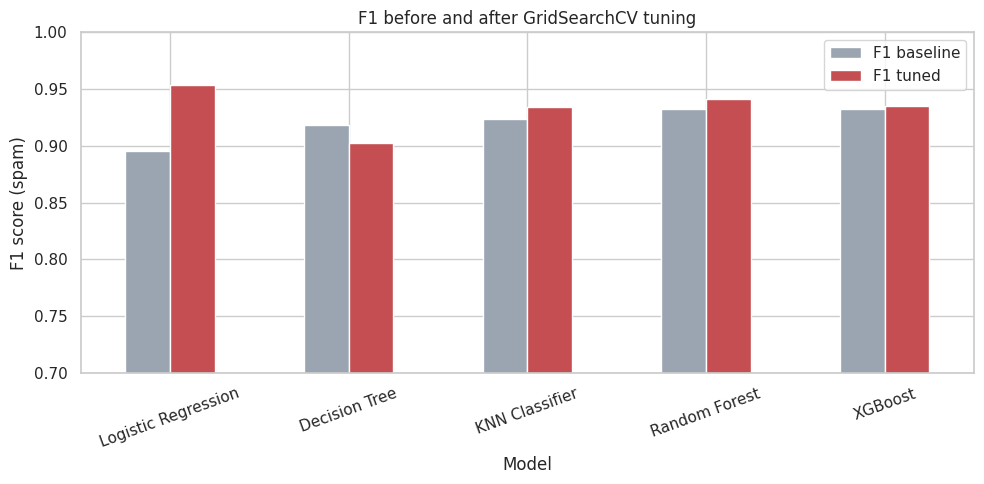

In [27]:
# Evaluate every tuned model on the untouched test set
print("TUNED MODEL RESULTS (test set)")
print("-" * 100)
TUNED_MODELS = []
for name, gs in grids.items():
    label = f"{name} (Tuned)"
    evaluate_model(label, gs.best_estimator_, X_test, y_test)
    TUNED_MODELS.append(label)

tuned_results = results_table(TUNED_MODELS)
print("\nTUNED MODEL PERFORMANCE TABLE (sorted by F1)")
display(tuned_results.round(4))

# Before vs after tuning
compare = []
for name in ["Logistic Regression", "Decision Tree", "KNN Classifier"]:
    compare.append({"Model": name, "F1 baseline": results[name]["F1 Score"], "F1 tuned": results[f"{name} (Tuned)"]["F1 Score"]})
compare.append({"Model": "Random Forest", "F1 baseline": results["Random Forest (Default)"]["F1 Score"], "F1 tuned": results["Random Forest (Tuned)"]["F1 Score"]})
compare.append({"Model": "XGBoost", "F1 baseline": results["XGBoost (Default)"]["F1 Score"], "F1 tuned": results["XGBoost (Tuned)"]["F1 Score"]})
compare = pd.DataFrame(compare)
compare["Change"] = compare["F1 tuned"] - compare["F1 baseline"]
print("\nF1 SCORE BEFORE AND AFTER TUNING")
display(compare.round(4))

compare.set_index("Model")[["F1 baseline", "F1 tuned"]].plot(kind="bar", figsize=(10, 5), color=["#9aa5b1", "#C44E52"])
plt.ylim(0.7, 1.0); plt.ylabel("F1 score (spam)"); plt.title("F1 before and after GridSearchCV tuning"); plt.xticks(rotation=20)
save_fig("09_tuning_effect")

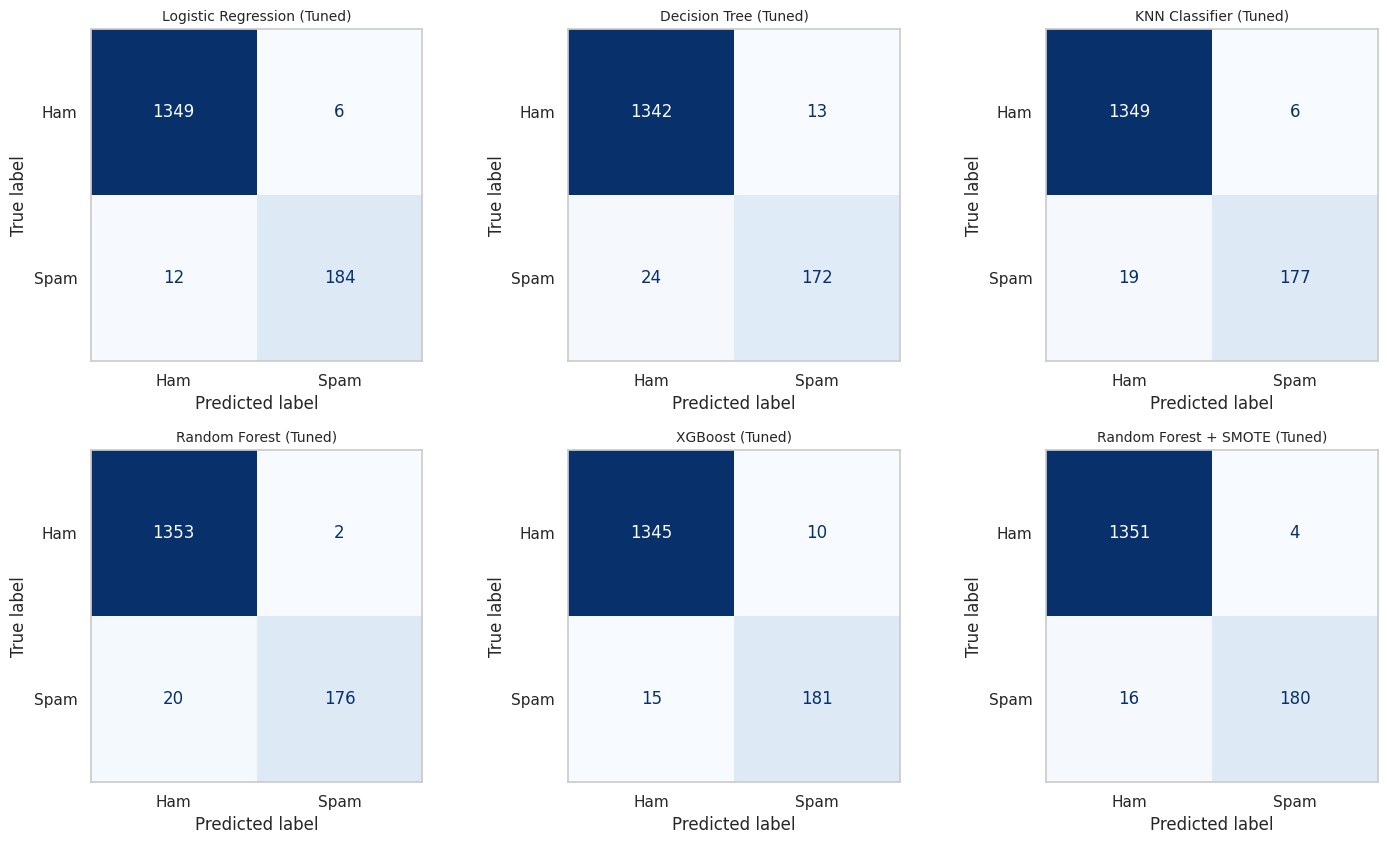

In [28]:
plot_confusion_matrices(TUNED_MODELS, ncols=3)
save_fig("10_tuned_confusion_matrices")

## 2.4 Cross-validation (5-fold stratified)

Cross-validation gives a more reliable estimate than a single split: every training message is used for validation exactly once. The mean and the standard deviation across the five folds are reported for **all** models (baseline settings and tuned settings). The test set is not used here.

done: Logistic Regression (Baseline)
done: Decision Tree (Baseline)
done: KNN Classifier (Baseline)
done: Random Forest (Default)
done: XGBoost (Default)
done: Logistic Regression (Tuned)
done: Decision Tree (Tuned)
done: KNN Classifier (Tuned)
done: Random Forest (Tuned)
done: XGBoost (Tuned)
done: Random Forest + SMOTE (Tuned)

CROSS-VALIDATION RESULTS (mean over 5 folds)


,Rank,Model,CV accuracy,CV precision,CV recall,CV f1,CV f1 std,CV roc_auc
0,1,Random Forest + SMOTE (Tuned),0.9909,0.9862,0.9409,0.9629,0.0129,0.9951
1,2,Logistic Regression (Tuned),0.9889,0.9752,0.9365,0.9552,0.0078,0.9932
2,3,XGBoost (Tuned),0.9878,0.9749,0.9277,0.9504,0.0153,0.9933
3,4,Random Forest (Tuned),0.9873,0.9859,0.9124,0.9475,0.0158,0.9946
4,5,XGBoost (Default),0.9862,0.9726,0.9167,0.9434,0.0129,0.9938
5,6,KNN Classifier (Tuned),0.9851,0.9651,0.9145,0.9390,0.0254,0.9762
6,7,Random Forest (Default),0.9851,0.9856,0.8949,0.9378,0.0166,0.9939
7,8,KNN Classifier (Baseline),0.9823,0.9547,0.9036,0.9280,0.0143,0.9775
8,9,Decision Tree (Tuned),0.9790,0.9440,0.8861,0.9136,0.0326,0.9295
9,10,Logistic Regression (Baseline),0.9771,0.9753,0.8402,0.9011,0.0348,0.9945


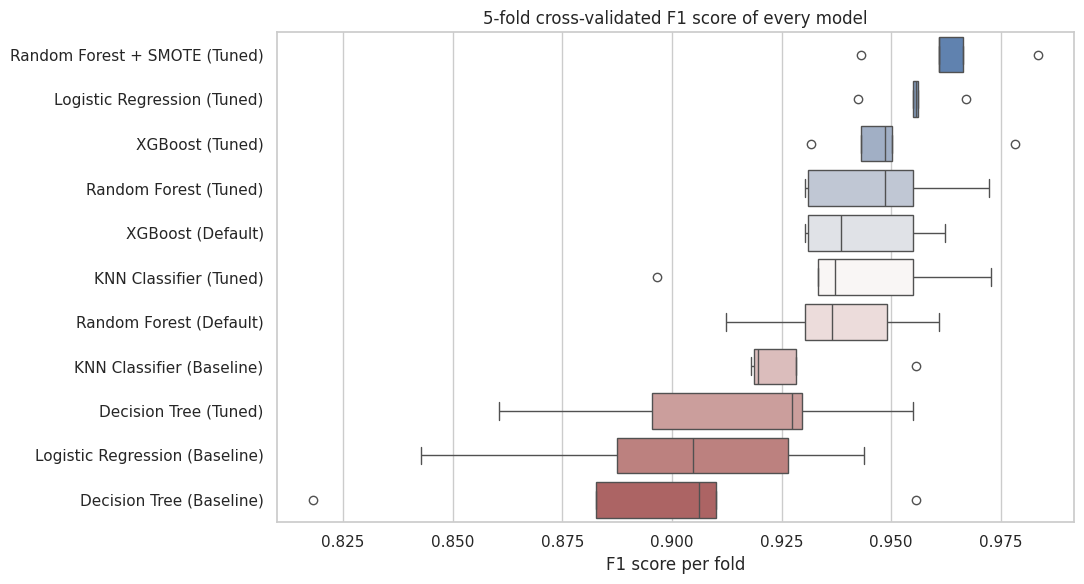

In [29]:
cv_models = {
    "Logistic Regression (Baseline)": clone(lr_base),
    "Decision Tree (Baseline)": clone(dt_base),
    "KNN Classifier (Baseline)": clone(knn_base),
    "Random Forest (Default)": clone(rf_default),
    "XGBoost (Default)": clone(xgb_default),
}
for n, gs in grids.items():
    cv_models[f"{n} (Tuned)"] = clone(gs.best_estimator_)

cv_rows, cv_f1_folds = [], {}
for name, mdl in cv_models.items():
    cvr = cross_validate(mdl, X_train, y_train, cv=cv5, scoring=scoring, n_jobs=-1)
    cv_f1_folds[name] = cvr["test_f1"]
    row = {"Model": name}
    for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
        row[f"CV {m}"] = cvr[f"test_{m}"].mean()
        row[f"CV {m} std"] = cvr[f"test_{m}"].std()
    cv_rows.append(row)
    print(f"done: {name}")

cv_results = pd.DataFrame(cv_rows).sort_values(["CV f1", "CV roc_auc"], ascending=False).reset_index(drop=True)
cv_results.insert(0, "Rank", range(1, len(cv_results) + 1))

print("\nCROSS-VALIDATION RESULTS (mean over 5 folds)")
display(cv_results[["Rank", "Model", "CV accuracy", "CV precision", "CV recall", "CV f1", "CV f1 std", "CV roc_auc"]].round(4))

plt.figure(figsize=(11, 6))
order_cv = cv_results["Model"].tolist()
sns.boxplot(data=pd.DataFrame(cv_f1_folds)[order_cv], orient="h", palette="vlag")
plt.xlabel("F1 score per fold"); plt.title("5-fold cross-validated F1 score of every model")
save_fig("11_cv_f1_boxplot")

In [30]:
top_cv = cv_results.iloc[0]
low_std = cv_results.sort_values("CV f1 std").iloc[0]
say(f"Interpretation (cross-validation): the best cross-validated model is {top_cv['Model']} with a mean F1 of {top_cv['CV f1']:.4f} "
    f"(+/- {top_cv['CV f1 std']:.4f}) and AUC of {top_cv['CV roc_auc']:.4f}. The most stable model across folds is {low_std['Model']} "
    f"(F1 standard deviation {low_std['CV f1 std']:.4f}). Small standard deviations mean the result does not depend on one lucky split. "
    f"Because the tuned models were selected with the same 5 folds, their CV scores are slightly optimistic; the untouched test set "
    f"gives the unbiased final check.")

Interpretation (cross-validation): the best cross-validated model is Random Forest + SMOTE (Tuned) with a mean
F1 of 0.9629 (+/- 0.0129) and AUC of 0.9951. The most stable model across folds is Logistic Regression (Tuned)
(F1 standard deviation 0.0078). Small standard deviations mean the result does not depend on one lucky split.
Because the tuned models were selected with the same 5 folds, their CV scores are slightly optimistic; the
untouched test set gives the unbiased final check.


## 2.5 ROC curve and AUC score

The **ROC curve** plots the True Positive Rate (recall of spam) against the False Positive Rate (genuine messages wrongly flagged) for every possible decision threshold. The **AUC** (area under the curve) summarises it in one number (1.0 = perfect, 0.5 = random guessing). Because spam is the minority class, the **precision-recall curve** is added as it is more informative for imbalanced data.

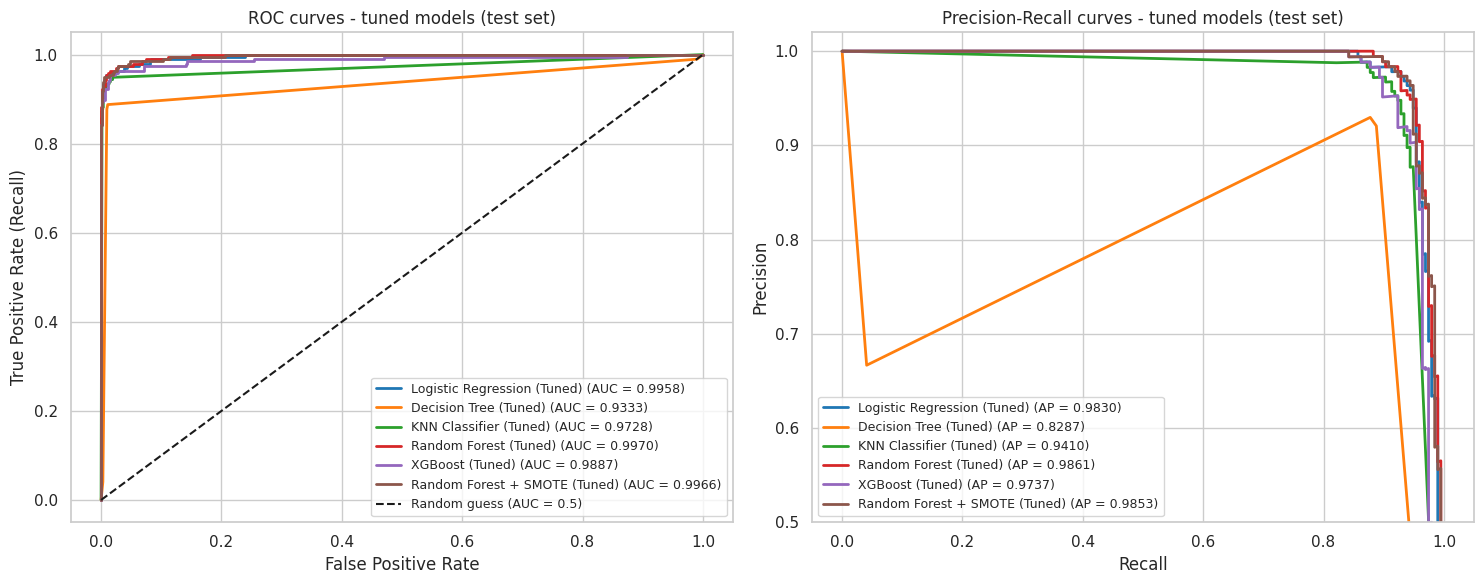

AUC SCORES (test set)


,Model,ROC AUC
0,Random Forest (Tuned),0.9970
1,Random Forest + SMOTE (Tuned),0.9966
2,Logistic Regression (Tuned),0.9958
3,Logistic Regression,0.9954
4,XGBoost (Tuned),0.9887
5,KNN Classifier,0.9746
6,KNN Classifier (Tuned),0.9728
7,Decision Tree,0.9427
8,Decision Tree (Tuned),0.9333


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
palette = sns.color_palette("tab10", len(TUNED_MODELS))

for colr, n in zip(palette, TUNED_MODELS):
    fpr, tpr, _ = roc_curve(y_test, probabilities[n])
    axes[0].plot(fpr, tpr, color=colr, lw=2, label=f"{n} (AUC = {results[n]['ROC AUC']:.4f})")
    prec, rec, _ = precision_recall_curve(y_test, probabilities[n])
    axes[1].plot(rec, prec, color=colr, lw=2, label=f"{n} (AP = {average_precision_score(y_test, probabilities[n]):.4f})")

axes[0].plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].set_title("ROC curves - tuned models (test set)"); axes[0].legend(loc="lower right", fontsize=9)
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curves - tuned models (test set)"); axes[1].legend(loc="lower left", fontsize=9)
axes[1].set_ylim(0.5, 1.02)
save_fig("12_roc_pr_curves")

auc_table = pd.DataFrame({
    "Model": TUNED_MODELS + BASELINE_MODELS,
    "ROC AUC": [results[n]["ROC AUC"] for n in TUNED_MODELS + BASELINE_MODELS],
}).sort_values("ROC AUC", ascending=False).reset_index(drop=True)
print("AUC SCORES (test set)")
display(auc_table.round(4))

In [32]:
best_auc = auc_table[auc_table["Model"].isin(TUNED_MODELS)].iloc[0]
say(f"Interpretation (ROC / AUC): every tuned model has an AUC well above 0.5; the highest AUC among them is {best_auc['Model']} with "
    f"{best_auc['ROC AUC']:.4f}. Curves that hug the top-left corner separate spam from ham almost perfectly: at a very low false-positive "
    f"rate they already catch most spam. Ensembles and Logistic Regression usually lead on text data, while a single Decision "
    f"Tree and KNN tend to have lower AUC because their probability estimates are coarse (compare the AUC values in the table). Since AUC is threshold independent, the decision "
    f"threshold can still be moved (section 4.3) to trade fewer blocked genuine messages against fewer missed spam messages.")

Interpretation (ROC / AUC): every tuned model has an AUC well above 0.5; the highest AUC among them is Random
Forest (Tuned) with 0.9970. Curves that hug the top-left corner separate spam from ham almost perfectly: at a
very low false-positive rate they already catch most spam. Ensembles and Logistic Regression usually lead on
text data, while a single Decision Tree and KNN tend to have lower AUC because their probability estimates are
coarse (compare the AUC values in the table). Since AUC is threshold independent, the decision threshold can
still be moved (section 4.3) to trade fewer blocked genuine messages against fewer missed spam messages.


## 2.6 Week 2 — explanation of the tuned results

In [33]:
tbest = tuned_results.iloc[0]
gain = compare.sort_values("Change", ascending=False).iloc[0]
say(f"Explanation: after GridSearchCV the best tuned model on the test set is {tbest['Model']} (F1 = {tbest['F1 Score']:.4f}, precision = "
    f"{tbest['Precision']:.4f}, recall = {tbest['Recall']:.4f}, AUC = {tbest['ROC AUC']:.4f}). Tuning helped most for {gain['Model']} "
    f"(F1 change {gain['Change']:+.4f}). Cross-validated tuning chooses regularisation strength (C), tree depth, number of trees / "
    f"boosting rounds, learning rate and the class-weight option using only the training data, which is why the test result is an "
    f"honest estimate of performance on new messages. Where gains are small, the baseline was already close to the ceiling of what "
    f"TF-IDF features can achieve on this data set; remaining errors are mostly borderline messages (e.g. genuine promotional-looking "
    f"texts or spam written like normal chat).")

Explanation: after GridSearchCV the best tuned model on the test set is Logistic Regression (Tuned) (F1 =
0.9534, precision = 0.9684, recall = 0.9388, AUC = 0.9958). Tuning helped most for Logistic Regression (F1
change +0.0578). Cross-validated tuning chooses regularisation strength (C), tree depth, number of trees /
boosting rounds, learning rate and the class-weight option using only the training data, which is why the test
result is an honest estimate of performance on new messages. Where gains are small, the baseline was already
close to the ceiling of what TF-IDF features can achieve on this data set; remaining errors are mostly
borderline messages (e.g. genuine promotional-looking texts or spam written like normal chat).


---
# WEEK 4 — Interpretation, Documentation & Deployment Insight

## 4.1 Final model selection justification

**Selection rule:** the final model is chosen with **cross-validation on the training data (mean F1, ties broken by AUC)** — *not* by looking at the test set, so the test result remains an unbiased estimate. Simplicity, speed and stability are also considered.

FINAL MODEL SELECTED: Random Forest + SMOTE (Tuned)
CV F1   : 0.9629 +/- 0.0129  (runner-up Logistic Regression (Tuned): 0.9552)
CV AUC  : 0.9951
TEST    : Accuracy=0.9871  Precision=0.9783  Recall=0.9184  F1=0.9474  AUC=0.9966
Best baseline test F1 = 0.9235  ->  change by the final model: +0.0239
Justification: Random Forest + SMOTE (Tuned) is selected because it has the highest cross-validated F1 score
(0.9629) of all 11 candidates, with a fold-to-fold standard deviation of 0.0129, and it keeps a high AUC
(0.9951), meaning it ranks spam above ham reliably at any threshold. On the untouched test set it reaches F1 =
0.9474 with precision 0.9783 and recall 0.9184, so it blocks very few genuine messages while catching most
spam. The CV and test scores are consistent, which indicates there is no serious over-fitting. The other
candidates were not selected because their cross-validated F1 was lower (see the ranking in 2.4). Note that
the test-set ranking can differ slightly from the CV ran

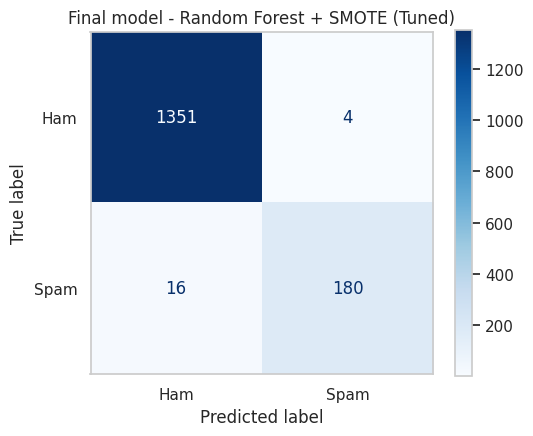

In [34]:
# Auto-generated, data-driven justification of the final model (selection = cross-validation, NOT the test set)
ranked = cv_results.copy()
winner, runner = ranked.iloc[0], ranked.iloc[1]
final_name = winner["Model"]
final_model = models[final_name] if final_name in models else clone(cv_models[final_name]).fit(X_train, y_train)
if final_name not in results:
    evaluate_model(final_name, final_model, X_test, y_test, verbose=False)
base_f1 = results_table(BASELINE_MODELS).iloc[0]["F1 Score"]
fin = results[final_name]
fin_pred = predictions[final_name]
fin_proba = probabilities[final_name]

print("FINAL MODEL SELECTED:", final_name)
print("=" * 78)
print(f"CV F1   : {winner['CV f1']:.4f} +/- {winner['CV f1 std']:.4f}  (runner-up {runner['Model']}: {runner['CV f1']:.4f})")
print(f"CV AUC  : {winner['CV roc_auc']:.4f}")
print(f"TEST    : Accuracy={fin['Accuracy']:.4f}  Precision={fin['Precision']:.4f}  Recall={fin['Recall']:.4f}  F1={fin['F1 Score']:.4f}  AUC={fin['ROC AUC']:.4f}")
print(f"Best baseline test F1 = {base_f1:.4f}  ->  change by the final model: {fin['F1 Score'] - base_f1:+.4f}")
print("=" * 78)
say(f"Justification: {final_name} is selected because it has the highest cross-validated F1 score ({winner['CV f1']:.4f}) of all "
    f"{len(ranked)} candidates, with a fold-to-fold standard deviation of {winner['CV f1 std']:.4f}, and it keeps a high AUC "
    f"({winner['CV roc_auc']:.4f}), meaning it ranks spam above ham reliably at any threshold. On the untouched test set it reaches "
    f"F1 = {fin['F1 Score']:.4f} with precision {fin['Precision']:.4f} and recall {fin['Recall']:.4f}, so it blocks very few genuine messages "
    f"while catching most spam. The CV and test scores are consistent, which indicates there is no serious over-fitting. "
    f"The other candidates were not selected because their cross-validated F1 was lower (see the ranking in 2.4). Note that the "
    f"test-set ranking can differ slightly from the CV ranking because the test set contains only {int(y_test.sum())} spam messages; the "
    f"selection deliberately follows the CV ranking so that the test set is not used to choose the model.")

print("\nCLASSIFICATION REPORT (test set)")
print(classification_report(y_test, fin_pred, target_names=["Ham", "Spam"], digits=4))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, fin_pred, display_labels=["Ham", "Spam"], cmap="Blues", ax=ax)
ax.set_title(f"Final model - {final_name}"); ax.grid(False)
save_fig("13_final_confusion_matrix")

## 4.2 Feature importance explanation

Three complementary views are used: **Logistic Regression coefficients** (direction: which words push a message towards spam or ham), **Random Forest importance** and **XGBoost importance** (how much each feature contributes to the trees' splits).

Logistic Regression coefficients of the NUMERIC descriptors (inputs scaled to [-1, 1]):
digit_count           17.38
msg_length             4.02
has_url                3.67
has_currency           3.33
upper_count            2.26
avg_word_length        2.10
word_count             1.27
special_char_count    -3.57


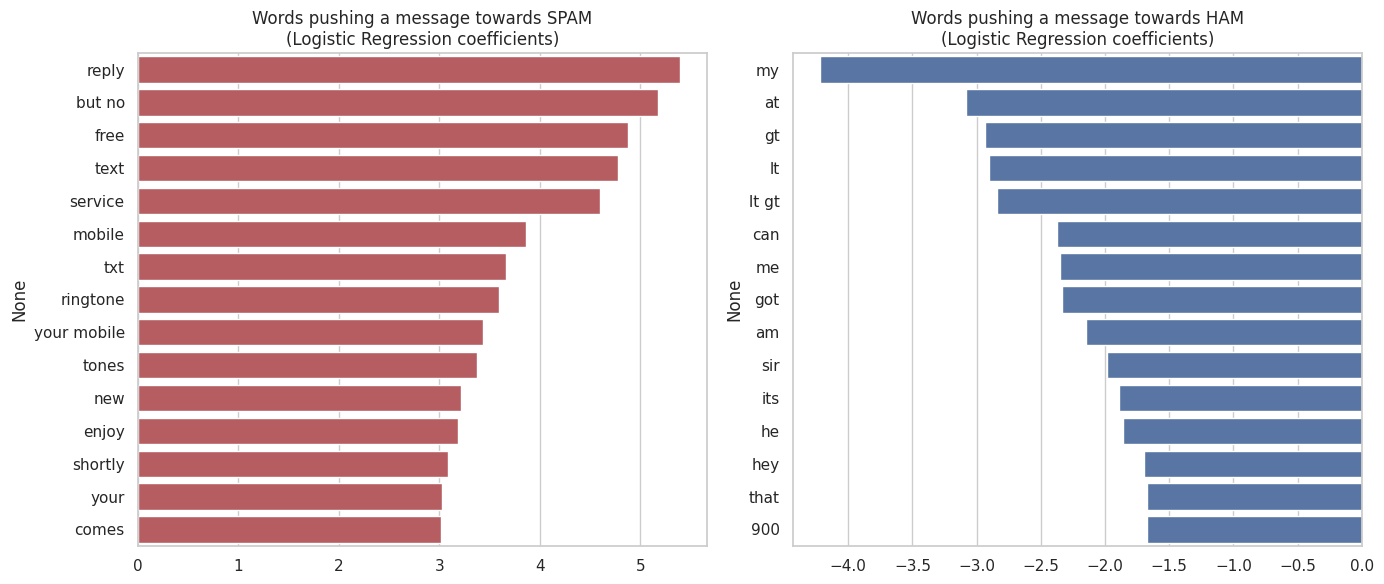

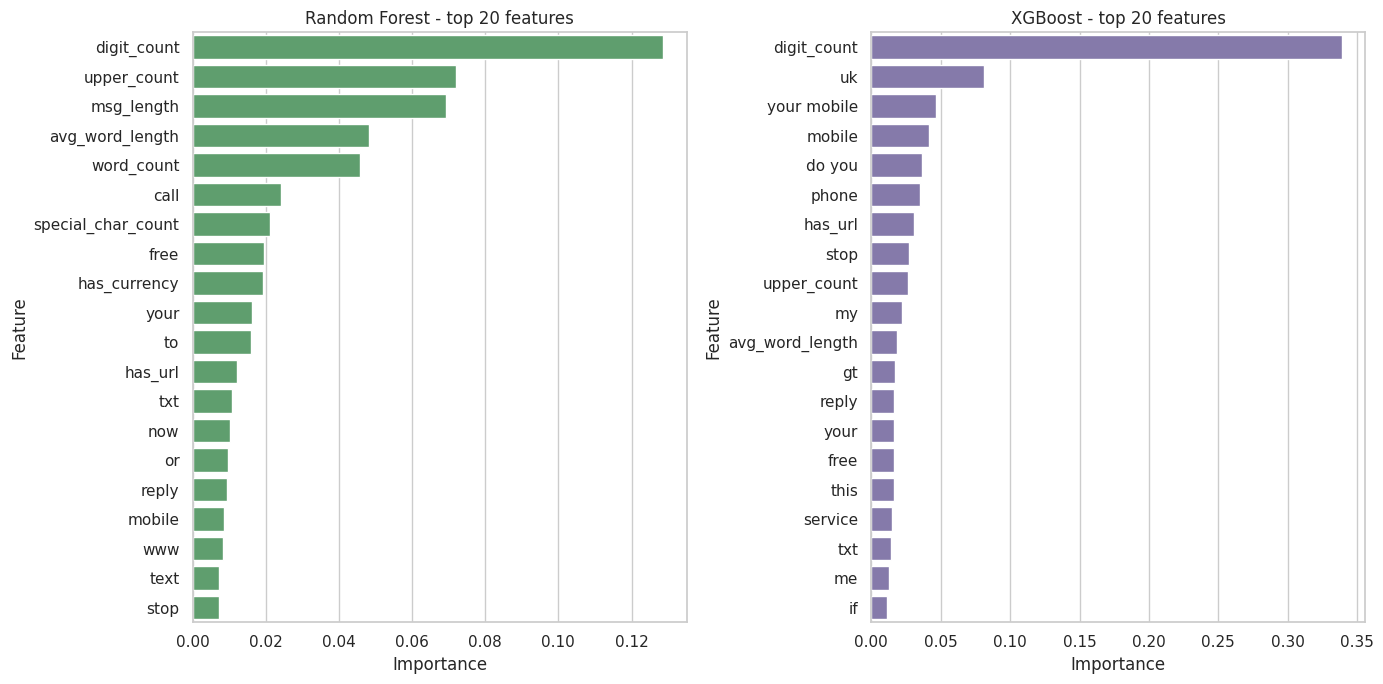

Top 10 features - Random Forest : digit_count, upper_count, msg_length, avg_word_length, word_count, call, special_char_count, free, has_currency, your
Top 10 features - XGBoost       : digit_count, uk, your mobile, mobile, do you, phone, has_url, stop, upper_count, my


In [35]:
def get_feature_names(pipe):
    names = pipe.named_steps["prep"].get_feature_names_out()
    return np.array([re.sub(r"^(tfidf|num)__", "", n) for n in names])

# 1) Logistic Regression coefficients (direction of influence)
lr_t = grids["Logistic Regression"].best_estimator_
lr_names = get_feature_names(lr_t)
coef_all = pd.Series(lr_t.named_steps["model"].coef_.ravel(), index=lr_names)
print("Logistic Regression coefficients of the NUMERIC descriptors (inputs scaled to [-1, 1]):")
print(coef_all[NUM_COLS].sort_values(ascending=False).round(2).to_string())
coef = coef_all.drop(NUM_COLS).sort_values()          # words / word pairs only
top_spam_terms = coef.sort_values(ascending=False).head(15)
top_ham_terms = coef.head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=top_spam_terms.values, y=top_spam_terms.index, color="#C44E52", ax=axes[0])
axes[0].set_title("Words pushing a message towards SPAM\n(Logistic Regression coefficients)")
sns.barplot(x=top_ham_terms.values, y=top_ham_terms.index, color="#4C72B0", ax=axes[1])
axes[1].set_title("Words pushing a message towards HAM\n(Logistic Regression coefficients)")
save_fig("14_lr_coefficients")

# 2) and 3) tree-based importances
def importance_frame(gs_name):
    est = grids[gs_name].best_estimator_
    return pd.DataFrame({"Feature": get_feature_names(est), "Importance": est.named_steps["model"].feature_importances_}) \
             .sort_values("Importance", ascending=False)

imp_rf, imp_xgb = importance_frame("Random Forest"), importance_frame("XGBoost")
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
sns.barplot(data=imp_rf.head(20), x="Importance", y="Feature", color="#55A868", ax=axes[0]); axes[0].set_title("Random Forest - top 20 features")
sns.barplot(data=imp_xgb.head(20), x="Importance", y="Feature", color="#8172B2", ax=axes[1]); axes[1].set_title("XGBoost - top 20 features")
save_fig("15_tree_feature_importance")

print("Top 10 features - Random Forest :", ", ".join(imp_rf.head(10)["Feature"]))
print("Top 10 features - XGBoost       :", ", ".join(imp_xgb.head(10)["Feature"]))

In [36]:
words_rf = set(imp_rf[~imp_rf["Feature"].isin(NUM_COLS)].head(15)["Feature"])
words_xgb = set(imp_xgb[~imp_xgb["Feature"].isin(NUM_COLS)].head(15)["Feature"])
common = words_rf & words_xgb & set(top_spam_terms.index)
num_rf = [f for f in imp_rf.head(10)["Feature"] if f in NUM_COLS]
num_xgb = [f for f in imp_xgb.head(10)["Feature"] if f in NUM_COLS]
say(f"Explanation (feature importance): in Logistic Regression the words that push a message most strongly towards SPAM are "
    f"{', '.join(top_spam_terms.index[:8])}; the words that push it towards HAM are {', '.join(top_ham_terms.index[:8])}. Spam is therefore "
    f"recognised by offer / call-to-action vocabulary and promotional wording, while ham is recognised by informal conversational words "
    f"(note: 'lt' and 'gt' come from the HTML codes &lt; &gt; that appear inside many genuine messages in the raw data). Words that are "
    f"important in all three views: {', '.join(sorted(common)) if common else 'none (the three views emphasise different words, which is normal because linear and tree models weigh features differently)'}. "
    f"Among the top-10 features of the tree models, the numeric descriptors are {', '.join(num_rf) or 'none'} (Random Forest) and "
    f"{', '.join(num_xgb) or 'none'} (XGBoost): digit_count and similar counts capture phone numbers, prices and short codes. "
    f"Overall the importance results agree with common sense about spam, which increases confidence that the models learned real patterns instead of noise.")

Explanation (feature importance): in Logistic Regression the words that push a message most strongly towards
SPAM are reply, but no, free, text, service, mobile, txt, ringtone; the words that push it towards HAM are my,
at, gt, lt, lt gt, can, me, got. Spam is therefore recognised by offer / call-to-action vocabulary and
promotional wording, while ham is recognised by informal conversational words (note: 'lt' and 'gt' come from
the HTML codes &lt; &gt; that appear inside many genuine messages in the raw data). Words that are important
in all three views: free, mobile, reply, txt, your. Among the top-10 features of the tree models, the numeric
descriptors are digit_count, upper_count, msg_length, avg_word_length, word_count, special_char_count,
has_currency (Random Forest) and digit_count, has_url, upper_count (XGBoost): digit_count and similar counts
capture phone numbers, prices and short codes. Overall the importance results agree with common sense about
spam, which increases confide

## 4.3 Business insights

SPAM vs HAM PROFILE


,Messages,Avg_length,Avg_digits,Avg_capitals,Pct_with_URL,Pct_with_currency
label,,,,,,
ham,4516,70.46,0.29,3.83,0.27,0.40
spam,653,137.89,15.45,15.23,17.76,33.23


FINAL MODEL ON 1551 UNSEEN MESSAGES: 180 spam caught | 16 spam missed | 4 genuine messages blocked | 1351 genuine delivered

DECISION-THRESHOLD TRADE-OFF


,Threshold,Precision,Recall,F1,Genuine blocked (FP),Spam missed (FN)
0,0.1,0.5145,0.9949,0.6783,184,1
1,0.2,0.7733,0.9745,0.8623,56,5
2,0.3,0.8905,0.9541,0.9212,23,9
3,0.4,0.9588,0.9490,0.9538,8,10
4,0.5,0.9783,0.9184,0.9474,4,16
5,0.6,0.9943,0.8929,0.9409,1,21
6,0.7,1.0000,0.8265,0.9050,0,34
7,0.8,1.0000,0.7347,0.8471,0,52
8,0.9,1.0000,0.5510,0.7105,0,88


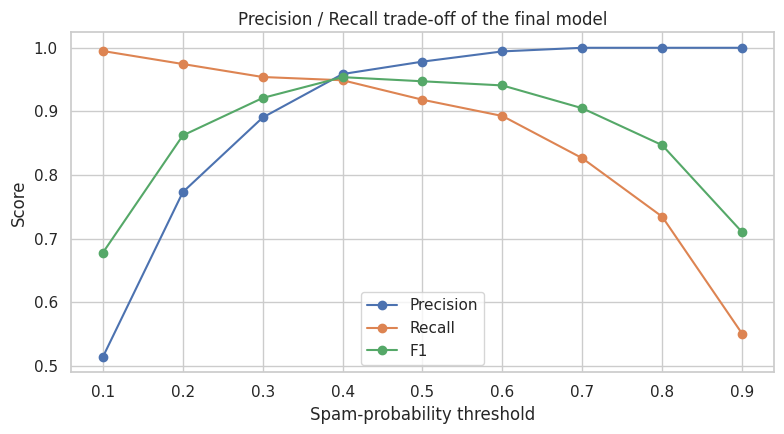

In [37]:
# ---------------------------------------------------------------
# Spam profile + error analysis + threshold trade-off for the final model
# ---------------------------------------------------------------
profile = df.groupby("label").agg(
    Messages=("message", "count"),
    Avg_length=("msg_length", "mean"),
    Avg_digits=("digit_count", "mean"),
    Avg_capitals=("upper_count", "mean"),
    Pct_with_URL=("has_url", lambda s: 100 * s.mean()),
    Pct_with_currency=("has_currency", lambda s: 100 * s.mean()),
).round(2)
print("SPAM vs HAM PROFILE")
display(profile)

tn, fp, fn, tp = confusion_matrix(y_test, fin_pred).ravel()
print(f"FINAL MODEL ON {len(y_test)} UNSEEN MESSAGES: {tp} spam caught | {fn} spam missed | {fp} genuine messages blocked | {tn} genuine delivered")

# Threshold trade-off (illustration on the test set; in production choose the threshold on validation data)
rows = []
for th in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    p = (fin_proba >= th).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, p).ravel()
    rows.append({"Threshold": th, "Precision": precision_score(y_test, p, zero_division=0), "Recall": recall_score(y_test, p),
                 "F1": f1_score(y_test, p), "Genuine blocked (FP)": fp_, "Spam missed (FN)": fn_})
threshold_table = pd.DataFrame(rows)
print("\nDECISION-THRESHOLD TRADE-OFF")
display(threshold_table.round(4))

plt.figure(figsize=(8, 4.5))
plt.plot(threshold_table["Threshold"], threshold_table["Precision"], marker="o", label="Precision")
plt.plot(threshold_table["Threshold"], threshold_table["Recall"], marker="o", label="Recall")
plt.plot(threshold_table["Threshold"], threshold_table["F1"], marker="o", label="F1")
plt.xlabel("Spam-probability threshold"); plt.ylabel("Score"); plt.title("Precision / Recall trade-off of the final model"); plt.legend()
save_fig("16_threshold_tradeoff")

In [38]:
# Which messages does the final model get wrong?
test_view = df.loc[X_test.index, ["label", "message"]].copy()
test_view["spam_probability"] = fin_proba
test_view["predicted"] = np.where(fin_pred == 1, "spam", "ham")

print("FALSE POSITIVES - genuine messages wrongly flagged as spam (most confident first)")
for _, r in test_view[(test_view["label"] == "ham") & (test_view["predicted"] == "spam")].sort_values("spam_probability", ascending=False).head(8).iterrows():
    print(f"  [{r['spam_probability']:.2f}] {textwrap.shorten(r['message'], 150)}")

print("\nFALSE NEGATIVES - spam that was missed (lowest score first)")
for _, r in test_view[(test_view["label"] == "spam") & (test_view["predicted"] == "ham")].sort_values("spam_probability").head(8).iterrows():
    print(f"  [{r['spam_probability']:.2f}] {textwrap.shorten(r['message'], 150)}")

FALSE POSITIVES - genuine messages wrongly flagged as spam (most confident first)
  [0.66] Hey...Great deal...Farm tour 9am to 5pm $95/pax, $50 deposit by 16 May
  [0.56] Hmm...Bad news...Hype park plaza $700 studio taken...Only left 2 bedrm-$900...
  [0.54] Hi Jon, Pete here, Ive bin 2 Spain recently & hav sum dinero left, Bill said u or ur åÔrents mayb interested in it, I hav 12,000pes, so around [...]
  [0.51] Funny fact Nobody teaches volcanoes 2 erupt, tsunamis 2 arise, hurricanes 2 sway aroundn no 1 teaches hw 2 choose a wife Natural disasters just [...]

FALSE NEGATIVES - spam that was missed (lowest score first)
  [0.07] Latest News! Police station toilet stolen, cops have nothing to go on!
  [0.11] RCT' THNQ Adrian for U text. Rgds Vatian
  [0.12] Hello. We need some posh birds and chaps to user trial prods for champneys. Can i put you down? I need your address and dob asap. Ta r
  [0.19] Would you like to see my XXX pics they are so hot they were nearly banned in the uk!
  [0

In [39]:
# Auto-generated business insights
sp, hm = profile.loc["spam"], profile.loc["ham"]
best_th = threshold_table.sort_values("F1", ascending=False).iloc[0]
hi_prec = threshold_table[(threshold_table["Precision"] >= 0.99)].sort_values("Recall", ascending=False)

print("BUSINESS INSIGHTS")
print("=" * 78)
insights = [
    f"1. Spam prevalence: about {n_spam/len(df)*100:.1f}% of the (unique) messages are spam, i.e. roughly 1 in {len(df)/n_spam:.0f} messages. Even a small spam share is "
    f"costly at the scale of millions of daily SMS.",
    f"2. Fingerprint of spam: spam messages are longer ({sp['Avg_length']:.0f} vs {hm['Avg_length']:.0f} characters), contain more digits "
    f"({sp['Avg_digits']:.1f} vs {hm['Avg_digits']:.1f}), more capital letters ({sp['Avg_capitals']:.1f} vs {hm['Avg_capitals']:.1f}) and use currency symbols "
    f"in {sp['Pct_with_currency']:.1f}% of cases (ham: {hm['Pct_with_currency']:.1f}%). Operators can use these cues for fast, cheap pre-filters.",
    f"3. Vocabulary: the strongest spam words are {', '.join(top_spam_terms.index[:6])}. These support rule-based blocklists, customer-awareness "
    f"campaigns and regulatory reporting of premium-rate scams.",
    f"4. Detection quality: the final model catches {tp} of {tp+fn} spam messages ({tp/(tp+fn)*100:.1f}% recall) in the test set while wrongly blocking only {fp} of "
    f"{fp+tn} genuine messages ({fp/(fp+tn)*100:.2f}%).",
    f"5. Error costs differ: blocking a genuine message (OTP, bank alert) is usually worse than letting one spam through. The threshold table shows the "
    f"trade-off: on the test set F1 is highest at threshold {best_th['Threshold']:.1f} ({best_th['F1']:.3f}; shown for illustration - in production the threshold should be chosen on validation data); " +
    (f"a stricter threshold of {hi_prec.iloc[0]['Threshold']:.1f} keeps precision >= 99% with recall {hi_prec.iloc[0]['Recall']:.3f}." if len(hi_prec) else
     "no tested threshold reaches 99% precision, so a human-review queue is advisable for borderline scores."),
    "6. Operating model: auto-block messages with a very high spam probability, send borderline scores (e.g. 0.4-0.7) to a quarantine / "
    "'report spam' folder or manual review, and always deliver low scores. This protects customers while keeping false alarms low.",
    "7. Value: automated filtering lowers support complaints and fraud exposure, improves customer trust and reduces manual moderation effort.",
]
for line in insights:
    say(line)
    print()

BUSINESS INSIGHTS
1. Spam prevalence: about 12.6% of the (unique) messages are spam, i.e. roughly 1 in 8 messages. Even a small
spam share is costly at the scale of millions of daily SMS.

2. Fingerprint of spam: spam messages are longer (138 vs 70 characters), contain more digits (15.4 vs 0.3),
more capital letters (15.2 vs 3.8) and use currency symbols in 33.2% of cases (ham: 0.4%). Operators can use
these cues for fast, cheap pre-filters.

3. Vocabulary: the strongest spam words are reply, but no, free, text, service, mobile. These support rule-
based blocklists, customer-awareness campaigns and regulatory reporting of premium-rate scams.

4. Detection quality: the final model catches 180 of 196 spam messages (91.8% recall) in the test set while
wrongly blocking only 4 of 1355 genuine messages (0.30%).

5. Error costs differ: blocking a genuine message (OTP, bank alert) is usually worse than letting one spam
through. The threshold table shows the trade-off: on the test set F1 is hig

## 4.4 Model limitations

1. **Small, old and narrow data:** only ~5,000 unique English messages collected around 2005–2012 (mostly UK / Singapore). Modern spam (QR codes, shortened links, WhatsApp / OTT scams, cryptocurrency, delivery-fee phishing) is under-represented.
2. **Language and style:** the model is English only; code-mixed text (e.g. Hinglish), other languages, emojis and unusual spelling are not covered.
3. **Class imbalance:** spam is only ~13% of the data, so rare spam types have very few examples; SMOTE creates synthetic points in TF-IDF space that may not be realistic messages.
4. **Bag-of-words limitation:** TF-IDF ignores word order and meaning (sarcasm, context, negation); it cannot tell a genuine "call me now" from a scam "call now".
5. **Adversarial behaviour / concept drift:** spammers deliberately change wording, spelling (fr33, w1n) and numbers; accuracy will decay over time unless the model is retrained.
6. **No sender or network information:** sender ID, sending frequency, URL reputation and user reports are strong signals that are not part of this data set.
7. **Text-only duplicates removed:** near-duplicates (same template with a different number) may still exist in both train and test sets and can make results slightly optimistic.
8. **Threshold / cost assumptions:** the 0.5 threshold is a default; real error costs are business-specific and unknown here.
9. **Single random split and small test set:** the test set has only a few hundred spam messages, so metrics have a noticeable margin of error (the CV standard deviation shows its size).

## 4.5 Future improvements

* **More and fresher data:** collect recent multilingual spam, use active learning with user "report spam" feedback and retrain regularly (drift monitoring).
* **Better text representations:** character n-grams (robust to obfuscation such as *fr33*), word embeddings, and **transformer models (BERT / DistilBERT, multilingual models)** for context understanding.
* **Extra signals:** sender ID, URL extraction and reputation, message frequency per sender, time of day, phone-number patterns.
* **Decision policy:** choose the threshold by cost-sensitive analysis, use calibrated probabilities and a three-way policy (deliver / quarantine / block).
* **Explainability:** SHAP or LIME explanations for every blocked message (useful for customer disputes and audits).
* **Robustness:** adversarial training with obfuscated spam, ensemble of the best linear and tree models.
* **Deployment:** serve the saved pipeline as a REST API / micro-service (Flask or FastAPI) or batch job, add logging, A/B testing and a human-in-the-loop review queue. *(A Streamlit / Flask demo is optional and not included in this notebook.)*

## 4.6 Deployment insight — saving the final model and predicting new messages

The final pipeline (TF-IDF + scaler + classifier) is saved as a single file; it can be loaded by any service and applied to new text. This is only a small *deployment insight* (no web app).

In [40]:
# Refit the final pipeline on the TRAINING data is already done; save it for reuse
joblib.dump(final_model, "spam_classifier_pipeline.joblib")
print("Saved:", "spam_classifier_pipeline.joblib", f"({os.path.getsize('spam_classifier_pipeline.joblib')/1024:.0f} KB)")

def predict_sms(messages, model=None, threshold=0.5):
    # Classify one or many SMS texts with the final pipeline.
    model = model or joblib.load("spam_classifier_pipeline.joblib")
    frame = add_features(pd.DataFrame({"message": list(messages)}))
    proba = model.predict_proba(frame[INPUT_COLS])[:, 1]
    return pd.DataFrame({"message": list(messages), "spam_probability": proba.round(3),
                         "prediction": np.where(proba >= threshold, "SPAM", "HAM")})

examples = [
    "Congratulations! You have won a 1000 pound cash prize. Call 09061701461 now to claim. T&Cs apply.",
    "URGENT! Your mobile number has been selected for a FREE holiday. Text WIN to 80082 to claim",
    "Hey, are we still meeting for lunch at 1pm? Let me know if you want to change the place.",
    "Can you send me the notes from yesterday's class? I will return the book tomorrow.",
    "Your account is blocked. Click http://bit.ly/secure-bank-login to verify within 24 hours.",
]
display(predict_sms(examples, model=final_model))

Saved: spam_classifier_pipeline.joblib (4299 KB)


,message,spam_probability,prediction
0,Congratulations! You have won a 1000 pound cash prize. Call 09061701461 now to claim. T&Cs apply.,0.979,SPAM
1,URGENT! Your mobile number has been selected for a FREE holiday. Text WIN to 80082 to claim,0.939,SPAM
2,"Hey, are we still meeting for lunch at 1pm? Let me know if you want to change the place.",0.012,HAM
3,Can you send me the notes from yesterday's class? I will return the book tomorrow.,0.046,HAM
4,Your account is blocked. Click http://bit.ly/secure-bank-login to verify within 24 hours.,0.452,HAM


## 4.7 Conclusion

In [41]:
print("CONCLUSION")
print("=" * 70)
say(f"The SMS Spam Detection project applied supervised classification to separate spam from legitimate text messages. After exploratory "
    f"analysis (missing values, duplicates, class balance, distributions, outliers, correlations), messages were encoded with TF-IDF plus eight "
    f"numeric descriptors and split 70:30 (stratified). Logistic Regression, Decision Tree and KNN were used as baselines (best baseline F1 = "
    f"{base_f1:.3f}), followed by Random Forest and XGBoost, class-imbalance handling (class weights and SMOTE), GridSearchCV tuning and "
    f"5-fold stratified cross-validation. {final_name} was selected on cross-validated F1 and reaches on the unseen test set accuracy = "
    f"{fin['Accuracy']:.4f}, precision = {fin['Precision']:.4f}, recall = {fin['Recall']:.4f}, F1 = {fin['F1 Score']:.4f} and AUC = {fin['ROC AUC']:.4f}. "
    f"Feature importance shows that promotional / call-to-action words, digits and message length drive the predictions. The main "
    f"limitations are the small, dated, English-only data and the bag-of-words representation; future work should add fresh multilingual "
    f"data, sender / URL signals, transformer models and continuous monitoring.")

CONCLUSION
The SMS Spam Detection project applied supervised classification to separate spam from legitimate text
messages. After exploratory analysis (missing values, duplicates, class balance, distributions, outliers,
correlations), messages were encoded with TF-IDF plus eight numeric descriptors and split 70:30 (stratified).
Logistic Regression, Decision Tree and KNN were used as baselines (best baseline F1 = 0.923), followed by
Random Forest and XGBoost, class-imbalance handling (class weights and SMOTE), GridSearchCV tuning and 5-fold
stratified cross-validation. Random Forest + SMOTE (Tuned) was selected on cross-validated F1 and reaches on
the unseen test set accuracy = 0.9871, precision = 0.9783, recall = 0.9184, F1 = 0.9474 and AUC = 0.9966.
Feature importance shows that promotional / call-to-action words, digits and message length drive the
predictions. The main limitations are the small, dated, English-only data and the bag-of-words representation;
future work should add fre